# МАГІСТЕРСЬКА КВАЛІФІКАЦІЙНА РОБОТА (ПОВНИЙ ОБЧИСЛЮВАЛЬНИЙ КОМПЛЕКС)
## «Ідентифікація параметрів коливань закріпленої струни на основі методу головних компонентів (PCA) та регресійних моделей машинного навчання»

Цей Jupyter Notebook містить повний код, розрахункові таблиці (**Таблиці 2.1–2.8 та 4.1–4.8**, усього 16 таблиць) та графічні ілюстрації (**Рисунки 2.1–2.9, 3.1–3.2 та 4.1–4.9**, усього 20 рисунків), структуровані строго за розділами дипломної роботи:
1. **РОЗДІЛ 2.** Розв’язання та аналіз прямої задачі коливань струни (Підрозділи 2.1–2.4).
2. **РОЗДІЛ 3.** Обернена задача та методика її розв’язання на основі методу головних компонентів (PCA) та машинного навчання (Підрозділи 3.1–3.5).
3. **РОЗДІЛ 4.** Числові експерименти та аналіз результатів ідентифікації параметрів струни (Підрозділи 4.1–4.7).

# РОЗДІЛ 2. РОЗВ’ЯЗАННЯ ТА АНАЛІЗ ПРЯМОЇ ЗАДАЧІ КОЛИВАНЬ СТРУНИ

Магістерська робота: **«Ідентифікація параметрів коливань закріпленої струни на основі методу головних компонентів (PCA) та регресійних моделей машинного навчання»**

У цьому ноутбуці реалізовано повний цикл аналітичного та чисельного моделювання **прямої задачі** вільних поперечних коливань однорідної пружної струни, жорстко закріпленої на кінцях $x=0$ та $x=l$:
- **Підрозділ 2.1.** Математична постановка початково-крайової задачі та базові фізичні параметри системи.
- **Підрозділ 2.2.** Побудова аналітичного розв’язку методом відокремлення змінних (Фур’є) (**Рисунок 2.1**).
- **Підрозділ 2.3.** Дослідження збіжності тригонометричного ряду за критерієм Коші ($N \to 2N$) та вибір кількості гармонік $K=41$ для досягнення відносної похибки $\varepsilon = 10^{-6}$ (**Таблиці 2.1, 2.2**, **Рисунок 2.2**).
- **Підрозділ 2.4.** Параметричний аналіз хвильового поля $U(x,t)$ при варіації фазової швидкості $a$, довжини струни $l$ та кривини початкового прогину $A$ (**Таблиці 2.3–2.8**, **Рисунки 2.3–2.9**).

## 2.1. Постановка задачі та базові фізичні параметри моделі

Рівняння вільних поперечних коливань однорідної струни має вигляд:
$$\frac{\partial^2 U}{\partial t^2} = a^2 \frac{\partial^2 U}{\partial x^2}, \quad 0 < x < l, \quad t > 0$$

із однорідними граничними умовами Діріхле (жорстке закріплення кінців):
$$U(0, t) = 0, \quad U(l, t) = 0, \quad t \ge 0$$

та початковими умовами параболічного відтягнення без початкової швидкості:
$$U(x, 0) = \varphi(x) = A x (l - x), \quad \left.\frac{\partial U}{\partial t}\right|_{t=0} = 0, \quad x \in [0, l].$$

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

mpl.rcParams["font.family"] = "DejaVu Serif"
mpl.rcParams["mathtext.fontset"] = "stix"
mpl.rcParams["axes.unicode_minus"] = True

# Базові параметри фізичної системи (у системі СІ)
l = 1.0          # Довжина струни між опорами, м
a = 1.0          # Фазова швидкість поширення хвилі, м/с
A = 1.0          # Параметр кривини початкового параболічного прогину, м^-1
h_max = A * (l ** 2) / 4.0  # Максимальний початковий прогин у центрі h = Al^2/4, м
T_period = 2.0 * l / a      # Основний період власних коливань T = 2l/a, с
eps_target = 1e-6           # Цільовий поріг відносної похибки ряду Фур'є
Nx, Nt = 200, 400

def U_func(x, t, K=41, a_val=1.0, l_val=1.0, A_val=1.0):
    """Часткова сума ряду Фур'є з K непарних гармонік (формула (2.27))."""
    k = np.arange(0, K, dtype=np.float64)
    m = 2.0 * k + 1.0
    coeff = 8.0 * A_val * (l_val ** 2) / (np.pi ** 3)
    terms = (coeff / (m ** 3)) * np.cos(m * np.pi * a_val * t / l_val) * np.sin(m * np.pi * x / l_val)
    return float(np.sum(terms))

def U_func_grid(X, T, K=41, a_val=1.0, l_val=1.0, A_val=1.0):
    """Векторизоване обчислення хвильового поля U(x, t) на сітці (X, T)."""
    res = np.zeros_like(X, dtype=np.float64)
    coeff = 8.0 * A_val * (l_val ** 2) / (np.pi ** 3)
    for k in range(K):
        m = 2.0 * k + 1.0
        res += (coeff / (m ** 3)) * np.cos(m * np.pi * a_val * T / l_val) * np.sin(m * np.pi * X / l_val)
    return res

def U_dalembert_exact(x, t, a_val=1.0, l_val=1.0, A_val=1.0):
    """Точний аналітичний розв'язок у формі Даламбера (формула (2.26))."""
    def phi_ext(xi):
        period = 2.0 * l_val
        r = xi % period
        if r <= l_val:
            return A_val * r * (l_val - r)
        r2 = period - r
        return -A_val * r2 * (l_val - r2)
    return 0.5 * (phi_ext(x - a_val * t) + phi_ext(x + a_val * t))

def fmt_sci_ua(val, decimals=4):
    if val == 0:
        return "0,00"
    exp = int(np.floor(np.log10(abs(val))))
    mant = val / (10.0 ** exp)
    return f"{mant:.{decimals}f}".replace(".", ",") + f"·10^{exp}"

print("=" * 85)
print("Підрозділ 2.1. Базові фізичні параметри системи (СІ):")
print(f"  1. Довжина струни між опорами       : l = {l:.2f} м")
print(f"  2. Фазова швидкість хвилі           : a = {a:.2f} м/с")
print(f"  3. Параметр кривини параболи        : A = {A:.2f} м^-1")
print(f"  4. Стріла початкового прогину       : h = phi(l/2) = A*l^2/4 = {h_max:.4f} м")
print(f"  5. Основний період коливань         : T = 2l/a = {T_period:.3f} с (f1 = {1.0/T_period:.3f} Гц)")
print(f"  6. Задана границя відносної похибки : eps = {eps_target:.1e}")
print("=" * 85)

Підрозділ 2.1. Базові фізичні параметри системи (СІ):
  1. Довжина струни між опорами       : l = 1.00 м
  2. Фазова швидкість хвилі           : a = 1.00 м/с
  3. Параметр кривини параболи        : A = 1.00 м^-1
  4. Стріла початкового прогину       : h = phi(l/2) = A*l^2/4 = 0.2500 м
  5. Основний період коливань         : T = 2l/a = 2.000 с (f1 = 0.500 Гц)
  6. Задана границя відносної похибки : eps = 1.0e-06


## 2.2. Побудова аналітичного розв’язку методом відокремлення змінних (Фур’є) (**Рисунок 2.1**)

Аналітичний розв’язок задачі подається у вигляді тригонометричного ряду за непарними гармоніками $n = 2k+1$ (формула (2.24)):
$$U(x, t) = \frac{8 A l^2}{\pi^3} \sum_{k=0}^{\infty} \frac{1}{(2k+1)^3} \cos\!\left(\frac{(2k+1)\pi a t}{l}\right) \sin\!\left(\frac{(2k+1)\pi x}{l}\right).$$

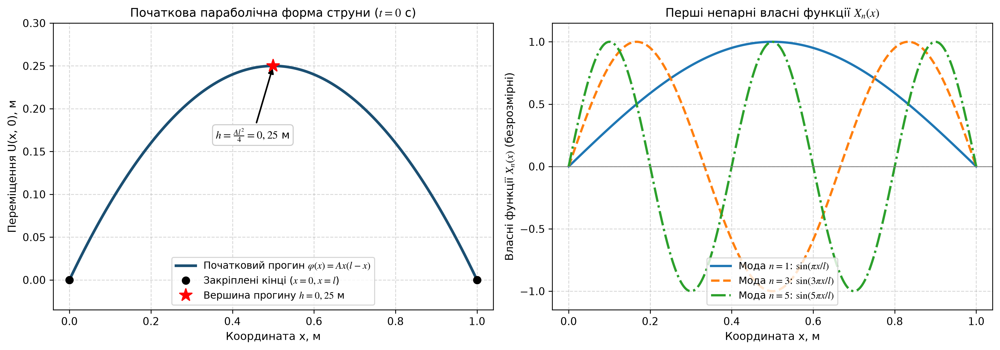

In [2]:
# Рисунок 2.1: Профіль початкового параболічного прогину струни phi(x) = Ax(l-x) (а)
# та просторові форми перших непарних власних мод коливань X_n(x) = sin(n*pi*x/l) при n=1,3,5 (б)
x_plot = np.linspace(0.0, l, 400)
phi_plot = A * x_plot * (l - x_plot)

fig2_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)

ax1.plot(x_plot, phi_plot, color="#1b4f72", lw=2.6, label=r"Початковий прогин $\varphi(x) = Ax(l - x)$")
ax1.plot([0.0, l], [0.0, 0.0], "ko", ms=7, label=r"Закріплені кінці ($x = 0, x = l$)")
ax1.plot(0.5 * l, h_max, "r*", ms=13, zorder=5, label=r"Вершина прогину $h = 0,25$ м")
ax1.annotate(
    r"$h = \frac{Al^2}{4} = 0,25$ м",
    xy=(0.5 * l, h_max), xytext=(0.45 * l, 0.165), ha="center", fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc"),
    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="black"),
)
ax1.set_title("Початкова параболічна форма струни ($t = 0$ с)", fontsize=11.5)
ax1.set_xlabel("Координата x, м", fontsize=10.5)
ax1.set_ylabel("Переміщення U(x, 0), м", fontsize=10.5)
ax1.set_xlim(-0.04, 1.04)
ax1.set_ylim(-0.035, 0.30)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower center", fontsize=9.5, frameon=True)

modes_cfg = [
    (1, "-", "#1f77b4", r"Мода $n = 1$: $\sin(\pi x/l)$"),
    (3, "--", "#ff7f0e", r"Мода $n = 3$: $\sin(3\pi x/l)$"),
    (5, "-.", "#2ca02c", r"Мода $n = 5$: $\sin(5\pi x/l)$"),
]
for n_mode, ls, col, lbl in modes_cfg:
    ax2.plot(x_plot, np.sin(n_mode * np.pi * x_plot / l), linestyle=ls, color=col, lw=2.2, label=lbl)
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_title(r"Перші непарні власні функції $X_n(x)$", fontsize=11.5)
ax2.set_xlabel("Координата x, м", fontsize=10.5)
ax2.set_ylabel(r"Власні функції $X_n(x)$ (безрозмірні)", fontsize=10.5)
ax2.set_xlim(-0.04, 1.04)
ax2.set_ylim(-1.15, 1.15)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower center", fontsize=9.5, frameon=True)

plt.tight_layout()
plt.show()

## 2.3. Дослідження збіжності ряду та оцінки похибки (**Таблиці 2.1, 2.2**, **Рисунок 2.2**)

Перевіряємо критерій Коші при подвоєнні кількості членів ряду $N \to 2N$ (**Таблиця 2.1**) та протокол досягнення відносної похибки $\delta_K \le 10^{-6}$ при $K = 41$ (**Таблиця 2.2**, **Рисунок 2.2**).

 ТАБЛИЦЯ 2.1 – Перевірка критерію Коші (N -> 2N) та порядку збіжності p у точці x = l/2, t = 0 
Кількість членів N | Подвоєна 2N  |  U_N(l/2,0), м  | U_2N(l/2,0), м  | Різниця Коші ΔU(N), м | Порядок p 
----------------------------------------------------------------------------------------------------
        16         |      32      |   0,24999609    |   0,24999951    |     3,4228·10^-6      |     –     
        32         |      64      |   0,24999951    |   0,24999994    |     4,2991·10^-7      |   2,9931  
        64         |     128      |   0,24999994    |   0,24999999    |     5,3804·10^-8      |   2,9983  
       128         |     256      |   0,24999999    |   0,25000000    |     6,7275·10^-9      |   2,9996  
       256         |     512      |   0,25000000    |   0,25000000    |     8,4100·10^-10     |   2,9999  
       512         |     1024     |   0,25000000    |   0,25000000    |     1,0513·10^-10     |   3,0000  
       1024        |     2048     |   0,25000000    | 

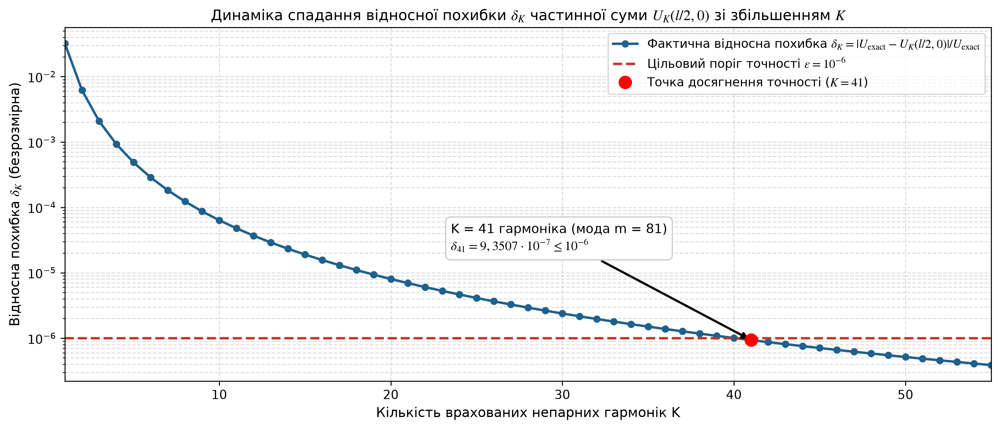

In [3]:
# Таблиця 2.1: Перевірка критерію Коші (N -> 2N) та порядку збіжності p
print("=" * 100)
print(" ТАБЛИЦЯ 2.1 – Перевірка критерію Коші (N -> 2N) та порядку збіжності p у точці x = l/2, t = 0 ")
print("=" * 100)
print(f"{'Кількість членів N':^18} | {'Подвоєна 2N':^12} | {'U_N(l/2,0), м':^15} | {'U_2N(l/2,0), м':^15} | {'Різниця Коші ΔU(N), м':^21} | {'Порядок p':^10}")
print("-" * 100)

N_list = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]
prev_diff = None
for N_val in N_list:
    N2_val = 2 * N_val
    u_N = U_func(0.5 * l, 0.0, N_val, a, l, A)
    u_2N = U_func(0.5 * l, 0.0, N2_val, a, l, A)
    diff = abs(u_2N - u_N)
    p_str = "–" if prev_diff is None else f"{np.log2(prev_diff / diff):.4f}".replace(".", ",")
    prev_diff = diff
    print(f"{N_val:^18d} | {N2_val:^12d} | {f'{u_N:.8f}'.replace('.', ','):^15} | {f'{u_2N:.8f}'.replace('.', ','):^15} | {fmt_sci_ua(diff, 4):^21} | {p_str:^10}")
print("=" * 100)

# Таблиця 2.2: Протокол прямого обчислення абсолютної R_K та відносної delta_K похибок
print("\n" + "=" * 105)
print(" ТАБЛИЦЯ 2.2 – Протокол прямого обчислення абсолютної R_K та відносної δ_K похибок ряду Фур’є до ε = 10^-6 ")
print("=" * 105)
print(f"{'Кількість членів K':^18} | {'Мода m=2K-1':^12} | {'Часткова сума U_K, м':^20} | {'Абс. похибка R_K, м':^19} | {'Відн. похибка δ_K':^19} | {'Умова δ_K ≤ 10^-6':^15}")
print("-" * 105)

K_protocol = [1, 2, 3, 5, 10, 20, 30, 40, 41, 50]
K_actual = 41
for K_val in K_protocol:
    m_val = 2 * K_val - 1
    u_k = U_func(0.5 * l, 0.0, K_val, a, l, A)
    R_k = abs(h_max - u_k)
    delta_k = R_k / h_max
    cond_str = "виконано" if delta_k <= eps_target else "не виконано"
    print(f"{K_val:^18d} | {m_val:^12d} | {f'{u_k:.8f}'.replace('.', ','):^20} | {fmt_sci_ua(R_k, 4):^19} | {fmt_sci_ua(delta_k, 4):^19} | {cond_str:^15}")
print("=" * 105)

# Рисунок 2.2: Залежність відносної похибки delta_K від кількості утримуваних гармонік K
K_range = np.arange(1, 56)
deltas_all = np.array([abs(h_max - U_func(0.5 * l, 0.0, int(k_v), a, l, A)) / h_max for k_v in K_range])
delta_41 = deltas_all[40]

fig2_2, ax = plt.subplots(figsize=(11.5, 5.0), dpi=150)
ax.semilogy(K_range, deltas_all, "o-", color="#1f618d", lw=2.0, ms=5,
            label=r"Фактична відносна похибка $\delta_K = |U_{\mathrm{exact}} - U_K(l/2, 0)| / U_{\mathrm{exact}}$")
ax.axhline(eps_target, color="#c0392b", linestyle="--", lw=2.0, label=r"Цільовий поріг точності $\varepsilon = 10^{-6}$")
ax.plot(41, delta_41, "ro", ms=10, zorder=6, label=r"Точка досягнення точності ($K = 41$)")
ax.annotate("K = 41 гармоніка (мода m = 81)\n" + r"$\delta_{41} = 9,3507 \cdot 10^{-7} \leq 10^{-6}$",
            xy=(41, delta_41), xytext=(23.5, 2.2e-5), fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc"),
            arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
ax.set_title(r"Динаміка спадання відносної похибки $\delta_K$ частинної суми $U_K(l/2, 0)$ зі збільшенням $K$", fontsize=12)
ax.set_xlabel("Кількість врахованих непарних гармонік K", fontsize=11)
ax.set_ylabel(r"Відносна похибка $\delta_K$ (безрозмірна)", fontsize=11)
ax.set_xlim(1, 55)
ax.grid(True, which="both", linestyle="--", alpha=0.45)
ax.legend(loc="upper right", fontsize=10, frameon=True)
plt.tight_layout()
plt.show()

## 2.4. Аналіз прямої задачі

### 2.4.1. Просторово-часова матриця прогинів струни та фази стоячої хвилі (**Таблиця 2.3**, **Рисунок 2.3**)

 ТАБЛИЦЯ 2.3 – Просторово-часова матриця прогинів струни U(x_i, t_j), м, на одному періоді коливань (l=1,0 м, a=1,0 м/с, A=1,0 м^-1, K=41) 
x, м \ t, с |   0,0   |   0,2   |   0,4   |   0,5   |   0,6   |   0,8   |   1,0   |   1,2   |   1,5   |   1,8   |   2,0  
----------------------------------------------------------------------------------------------------------------------
  0,000    | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000  | 0,0000 
  0,125    | 0,1094  | 0,0750  | 0,0250  | 0,0000  | −0,0250 | −0,0750 | −0,1094 | −0,0750 | 0,0000  | 0,0750  | 0,1094 
  0,250    | 0,1875  | 0,1475  | 0,0500  | 0,0000  | −0,0500 | −0,1475 | −0,1875 | −0,1475 | 0,0000  | 0,1475  | 0,1875 
  0,375    | 0,2344  | 0,1944  | 0,0750  | 0,0000  | −0,0750 | −0,1944 | −0,2344 | −0,1944 | 0,0000  | 0,1944  | 0,2344 
  0,500    | 0,2500  | 0,2100  | 0,0900  | 0,0000  | −0,0900 | −0,2100 | −0,2500 | −0,2100 | 0,0000  | 0,2100  | 0,2500 
  0,625    | 0

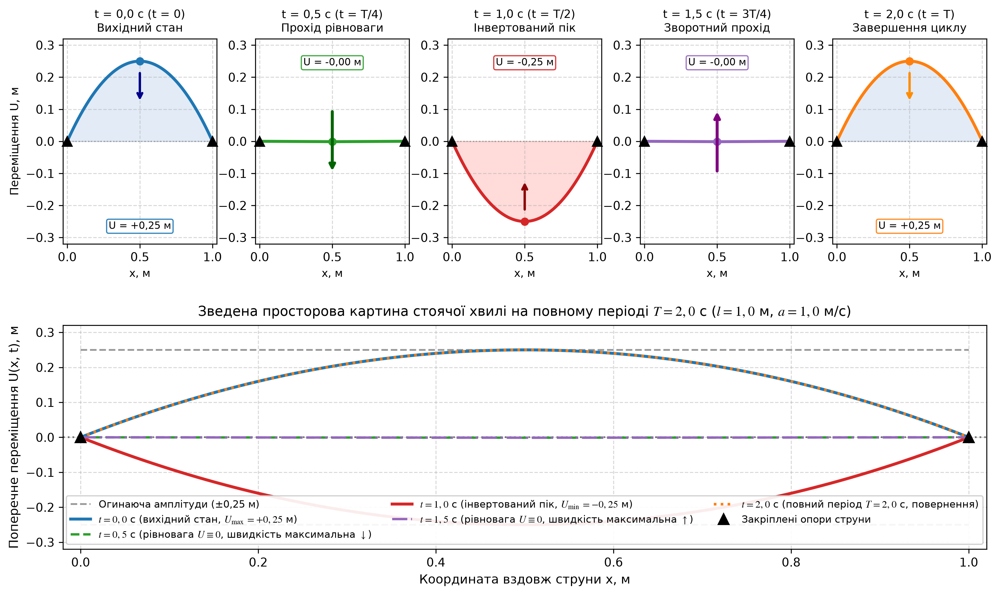

In [4]:
# Таблиця 2.3: Прямий розрахунок просторово-часової матриці прогинів U(x_i, t_j) за рядом Фур'є (K = 41)
x_nodes_23 = np.linspace(0.0, l, 9)
t_nodes_23 = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0]
table_2_3_rows = []
for xv in x_nodes_23:
    row_cells = [f"{xv:.3f}".replace(".", ",")]
    for tv in t_nodes_23:
        val = U_func(xv, tv, K_actual, a, l, A)
        if abs(val) < 5e-5:
            row_cells.append("0,0000")
        else:
            row_cells.append(f"{val:.4f}".replace(".", ",").replace("-", "−"))
    table_2_3_rows.append(row_cells)

print("=" * 118)
print(" ТАБЛИЦЯ 2.3 – Просторово-часова матриця прогинів струни U(x_i, t_j), м, на одному періоді коливань (l=1,0 м, a=1,0 м/с, A=1,0 м^-1, K=41) ")
print("=" * 118)
print(f"{'x, м \\ t, с':^10} | " + " | ".join([f"{str(t_v).replace('.', ','):^7}" for t_v in t_nodes_23]))
print("-" * 118)
for row in table_2_3_rows:
    print(f"{row[0]:^10} | " + " | ".join([f"{v:^7}" for v in row[1:]]))
print("=" * 118)

# Рисунок 2.3: Миттєві форми профілю коливної струни U(x, t) та зведена діаграма стоячої хвилі
x_arr = np.linspace(0.0, l, Nx)
t_arr = np.linspace(0.0, T_period, Nt)
X_mesh, T_mesh = np.meshgrid(x_arr, t_arr)
U_fourier = U_func_grid(X_mesh, T_mesh, K_actual, a, l, A)

fig2_3 = plt.figure(figsize=(14, 7.8), dpi=150)
gs = fig2_3.add_gridspec(2, 5, height_ratios=[1.1, 1.2], hspace=0.38, wspace=0.25)

times_23 = [0.0, 0.5, 1.0, 1.5, 2.0]
phase_labels = [
    "t = 0,0 с (t = 0)\nВихідний стан",
    "t = 0,5 с (t = T/4)\nПрохід рівноваги",
    "t = 1,0 с (t = T/2)\nІнвертований пік",
    "t = 1,5 с (t = 3T/4)\nЗворотний прохід",
    "t = 2,0 с (t = T)\nЗавершення циклу",
]
colors_23 = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#ff7f0e"]

for idx, (t_val, plabel, col) in enumerate(zip(times_23, phase_labels, colors_23)):
    ax = fig2_3.add_subplot(gs[0, idx])
    t_idx = np.argmin(np.abs(t_arr - t_val))
    u_prof = U_fourier[t_idx, :]
    u_center = u_prof[len(x_arr) // 2]

    ax.axhline(0, color="gray", linestyle=":", alpha=0.7, linewidth=1)
    if abs(u_center) > 1e-4:
        fill_col = "#aec7e8" if u_center > 0 else "#ff9896"
        ax.fill_between(x_arr, 0, u_prof, color=fill_col, alpha=0.35)

    ax.plot(x_arr, u_prof, color=col, linewidth=2.5)
    ax.plot(0, 0, "^k", markersize=8, clip_on=False)
    ax.plot(l, 0, "^k", markersize=8, clip_on=False)
    ax.plot(0.5, u_center, "o", color=col, markersize=6)
    ax.set_title(plabel, fontsize=9.5, pad=6)
    ax.set_ylim(-0.32, 0.32)
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("x, м", fontsize=9)
    if idx == 0:
        ax.set_ylabel("Переміщення U, м", fontsize=9.5)
    ax.grid(True, linestyle="--", alpha=0.5)

ax_bot = fig2_3.add_subplot(gs[1, :])
ax_bot.axhline(0, color="black", linestyle=":", alpha=0.5)
ax_bot.plot(x_arr, np.full_like(x_arr, 0.25), "k--", alpha=0.4, label="Огинаюча амплітуди (±0,25 м)")
ax_bot.plot(x_arr, np.full_like(x_arr, -0.25), "k--", alpha=0.4)

comp_labels = [
    r"$t = 0,0$ с (вихідний стан, $U_{\max} = +0,25$ м)",
    r"$t = 0,5$ с (рівновага $U \equiv 0$, швидкість максимальна $\downarrow$)",
    r"$t = 1,0$ с (інвертований пік, $U_{\min} = -0,25$ м)",
    r"$t = 1,5$ с (рівновага $U \equiv 0$, швидкість максимальна $\uparrow$)",
    r"$t = 2,0$ с (повний період $T = 2,0$ с, повернення)",
]
line_styles = ["-", "--", "-", "-.", ":"]
line_widths = [2.5, 2.0, 2.5, 2.0, 2.2]

for t_val, clabel, col, ls, lw in zip(times_23, comp_labels, colors_23, line_styles, line_widths):
    idx_t = np.argmin(np.abs(t_arr - t_val))
    ax_bot.plot(x_arr, U_fourier[idx_t, :], color=col, linestyle=ls, linewidth=lw, label=clabel)

ax_bot.plot(0, 0, "^k", markersize=9, label="Закріплені опори струни")
ax_bot.plot(l, 0, "^k", markersize=9)
ax_bot.set_title(r"Зведена просторова картина стоячої хвилі на повному періоді $T = 2,0$ с ($l = 1,0$ м, $a = 1,0$ м/с)", fontsize=11.5, pad=8)
ax_bot.set_xlabel("Координата вздовж струни x, м", fontsize=10.5)
ax_bot.set_ylabel("Поперечне переміщення U(x, t), м", fontsize=10.5)
ax_bot.set_xlim(-0.02, 1.02)
ax_bot.set_ylim(-0.32, 0.32)
ax_bot.grid(True, linestyle="--", alpha=0.5)
ax_bot.legend(loc="lower center", ncol=3, fontsize=8.5, framealpha=0.92)
plt.tight_layout()
plt.show()

### 2.4.2. Дослідження впливу фазової швидкості $a$ на спектральні та кінематичні характеристики (**Таблиця 2.4**, **Рисунки 2.4, 2.5, 2.6**)

 ТАБЛИЦЯ 2.4 – Вплив фазової швидкості a на спектральні, часові та кінематичні характеристики коливань струни 
Швидкість a, м/с | Період T=2l/a, с | Частота f1, Гц  | Циклів за Δt=2 с  | Макс. швидкість vmax | U(l/2, 0,1 с), м
----------------------------------------------------------------------------------------------------------------
      0,1        |      20,000      |      0,050      |        0,1        |        0,1000        |     +0,2499     
      1,0        |      2,000       |      0,500      |        1,0        |        1,0000        |     +0,2400     
      2,0        |      1,000       |      1,000      |        2,0        |        2,0000        |     +0,2100     
      5,0        |      0,400       |      2,500      |        5,0        |        5,0000        |      0,0000     
      10,0       |      0,200       |      5,000      |       10,0        |       10,0000        |     −0,2500     
     100,0       |      0,020       |     50,000      |       100,0       |     

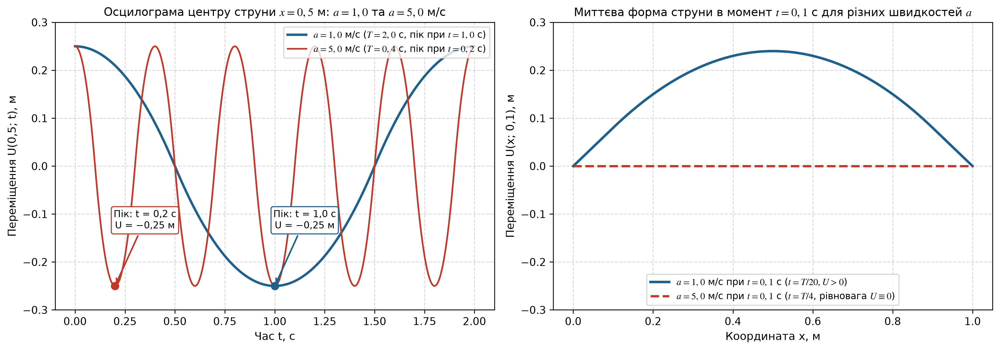

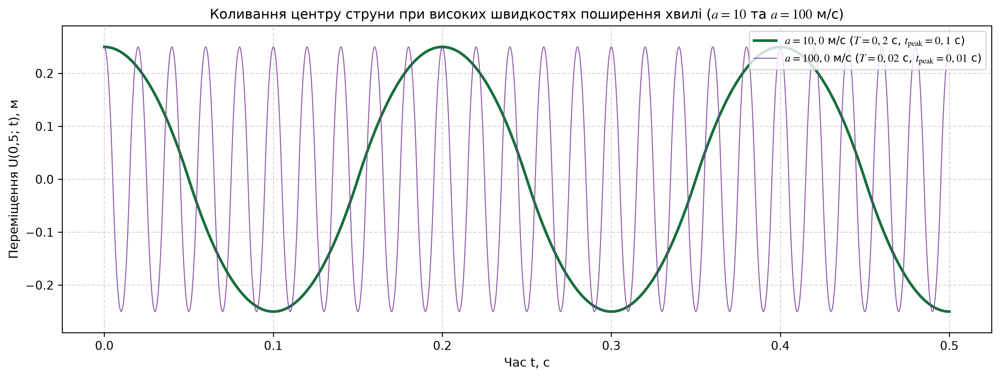

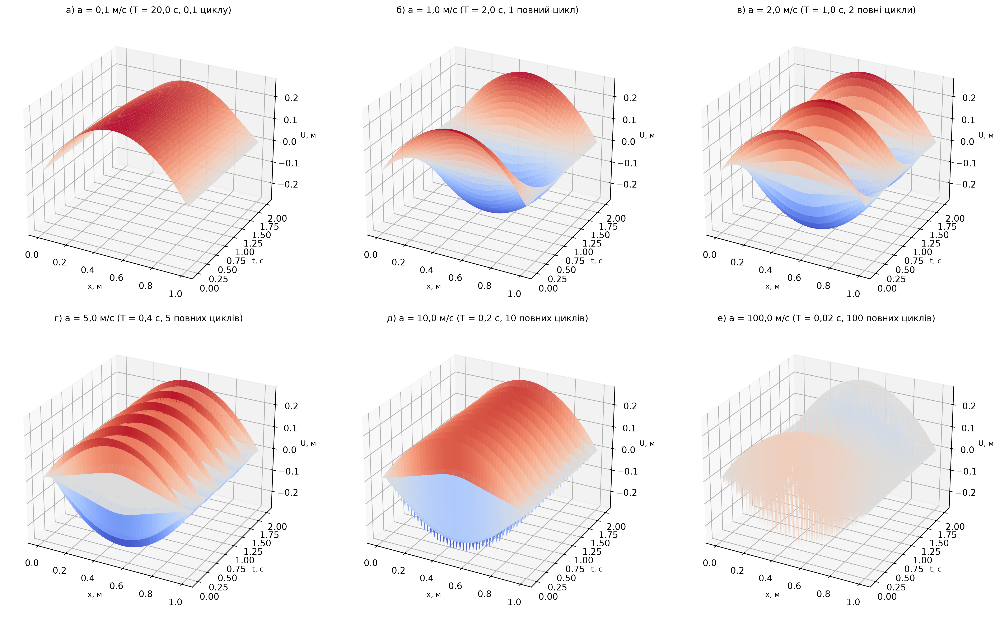

In [5]:
# Таблиця 2.4: Прямий розрахунок впливу фазової швидкості a на спектральні, часові та кінематичні характеристики
a_values = [0.1, 1.0, 2.0, 5.0, 10.0, 100.0]
table_2_4_rows = []
for a_v in a_values:
    T_v = 2.0 * l / a_v
    f1_v = 1.0 / T_v
    cycles_2s = 2.0 / T_v
    vmax_v = a_v * A * l
    u_t01 = U_func(0.5 * l, 0.1, K_actual, a_v, l, A)
    u_t01_str = "0,0000" if abs(u_t01) < 5e-5 else f"{u_t01:+.4f}".replace(".", ",").replace("-", "−")
    table_2_4_rows.append([
        f"{a_v:.1f}".replace(".", ","),
        f"{T_v:.3f}".replace(".", ","),
        f"{f1_v:.3f}".replace(".", ","),
        f"{cycles_2s:.1f}".replace(".", ","),
        f"{vmax_v:.4f}".replace(".", ","),
        u_t01_str,
    ])

print("=" * 112)
print(" ТАБЛИЦЯ 2.4 – Вплив фазової швидкості a на спектральні, часові та кінематичні характеристики коливань струни ")
print("=" * 112)
print(f"{'Швидкість a, м/с':^16} | {'Період T=2l/a, с':^16} | {'Частота f1, Гц':^15} | {'Циклів за Δt=2 с':^17} | {'Макс. швидкість vmax':^20} | {'U(l/2, 0,1 с), м':^16}")
print("-" * 112)
for row in table_2_4_rows:
    print(f"{row[0]:^16} | {row[1]:^16} | {row[2]:^15} | {row[3]:^17} | {row[4]:^20} | {row[5]:^16}")
print("=" * 112)

# Рисунок 2.4: Зіставлення коливань при a = 1,0 м/с та a = 5,0 м/с (а) та миттєві профілі в t = 0,1 с (б)
t_span = np.linspace(0.0, 2.0, 1000)
oscillations = {}
for a_val in a_values:
    u_c = np.zeros_like(t_span)
    for k in range(K_actual):
        m = 2 * k + 1
        u_c += (8.0 * A * (l ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k) * np.cos(m * np.pi * a_val * t_span / l)
    oscillations[a_val] = u_c

fig2_4, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)
ax1.plot(t_span, oscillations[1.0], color="#1f618d", lw=2.3, label=r"$a = 1,0$ м/с ($T = 2,0$ с, пік при $t = 1,0$ с)")
ax1.plot(t_span, oscillations[5.0], color="#c0392b", lw=1.6, label=r"$a = 5,0$ м/с ($T = 0,4$ с, пік при $t = 0,2$ с)")
ax1.plot(0.2, -0.25, "o", color="#c0392b", ms=7)
ax1.plot(1.0, -0.25, "o", color="#1f618d", ms=7)
ax1.set_title(r"Осцилограма центру струни $x = 0,5$ м: $a = 1,0$ та $a = 5,0$ м/с", fontsize=11)
ax1.set_xlabel("Час t, с", fontsize=10.5)
ax1.set_ylabel("Переміщення U(0,5; t), м", fontsize=10.5)
ax1.set_ylim(-0.30, 0.30)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", fontsize=9)

u_t01_a1 = np.array([U_func(xv, 0.1, K_actual, 1.0, l, A) for xv in x_plot])
u_t01_a5 = np.array([U_func(xv, 0.1, K_actual, 5.0, l, A) for xv in x_plot])
ax2.plot(x_plot, u_t01_a1, color="#1f618d", lw=2.4, label=r"$a = 1,0$ м/с при $t = 0,1$ с ($t = T/20, U > 0$)")
ax2.plot(x_plot, u_t01_a5, "--", color="#c0392b", lw=2.2, label=r"$a = 5,0$ м/с при $t = 0,1$ с ($t = T/4$, рівновага $U \equiv 0$)")
ax2.set_title(r"Миттєва форма струни в момент $t = 0,1$ с для різних швидкостей $a$", fontsize=11)
ax2.set_xlabel("Координата x, м", fontsize=10.5)
ax2.set_ylabel("Переміщення U(x; 0,1), м", fontsize=10.5)
ax2.set_ylim(-0.30, 0.30)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower center", fontsize=9)
plt.tight_layout()
plt.show()

# Рисунок 2.5: Високочастотні коливання на інтервалі t in [0; 0,5] с при a = 10 та a = 100 м/с
t_short = np.linspace(0.0, 0.5, 1500)
u_10 = np.zeros_like(t_short)
u_100 = np.zeros_like(t_short)
for k in range(K_actual):
    m = 2 * k + 1
    c_m = (8.0 * A * (l ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k)
    u_10 += c_m * np.cos(m * np.pi * 10.0 * t_short / l)
    u_100 += c_m * np.cos(m * np.pi * 100.0 * t_short / l)

fig2_5, ax = plt.subplots(figsize=(12.0, 4.6), dpi=150)
ax.plot(t_short, u_10, color="#196f3d", lw=2.3, label=r"$a = 10,0$ м/с ($T = 0,2$ с, $t_{\mathrm{peak}} = 0,1$ с)")
ax.plot(t_short, u_100, color="#7d3c98", lw=0.9, alpha=0.8, label=r"$a = 100,0$ м/с ($T = 0,02$ с, $t_{\mathrm{peak}} = 0,01$ с)")
ax.set_title(r"Коливання центру струни при високих швидкостях поширення хвилі ($a = 10$ та $a = 100$ м/с)", fontsize=11.5)
ax.set_xlabel("Час t, с", fontsize=10.5)
ax.set_ylabel("Переміщення U(0,5; t), м", fontsize=10.5)
ax.set_ylim(-0.29, 0.29)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", fontsize=9.5, frameon=True)
plt.tight_layout()
plt.show()

# Рисунок 2.6: Тривимірні просторово-часові поверхні хвильового поля U(x, t)
fig2_6 = plt.figure(figsize=(16.5, 10.0), dpi=150)
x_3d = np.linspace(0.0, l, 45)
t_3d = np.linspace(0.0, 2.0, 250)
X_3d, T_3d = np.meshgrid(x_3d, t_3d)
letters = ["а", "б", "в", "г", "д", "е"]
cycle_labels = ["0,1 циклу", "1 повний цикл", "2 повні цикли", "5 повних циклів", "10 повних циклів", "100 повних циклів"]

for idx, (a_v, let, c_lbl) in enumerate(zip(a_values, letters, cycle_labels), 1):
    ax3d = fig2_6.add_subplot(2, 3, idx, projection="3d")
    T_per = 2.0 * l / a_v
    U_sub = U_func_grid(X_3d, T_3d, 25, a_v, l, A)
    ax3d.plot_surface(X_3d, T_3d, U_sub, cmap="coolwarm", edgecolor="none", alpha=0.92, vmin=-0.25, vmax=0.25)
    t_per_str = f"{T_per:.1f}" if T_per >= 0.1 else f"{T_per:.2f}"
    ax3d.set_title(f"{let}) a = {str(a_v).replace('.', ',')} м/с (T = {t_per_str.replace('.', ',')} с, {c_lbl})", fontsize=10, pad=6)
    ax3d.set_xlabel("x, м", fontsize=8.5)
    ax3d.set_ylabel("t, с", fontsize=8.5)
    ax3d.set_zlabel("U, м", fontsize=8.5)
    ax3d.set_zlim(-0.28, 0.28)
    ax3d.view_init(elev=26, azim=-62)
plt.tight_layout()
plt.show()

### 2.4.3. Спільний вплив довжини струни $l$, параметра кривини $A$ та швидкості $a$ (**Рисунки 2.7, 2.8, 2.9**, **Таблиці 2.5–2.8**)

 ТАБЛИЦЯ 2.5 – Матриця значень максимального початкового прогину струни h(A, l) = A*l^2/4, м 
 Кривина A \ Довжина l   |  l = 0,5   |  l = 1,0   |  l = 1,5   |  l = 2,0  
--------------------------------------------------------------------------------
        A = 0,5          |  0,03125   |  0,12500   |  0,28125   |  0,50000  
        A = 1,0          |  0,06250   |  0,25000   |  0,56250   |  1,00000  
        A = 1,5          |  0,09375   |  0,37500   |  0,84375   |  1,50000  
        A = 2,0          |  0,12500   |  0,50000   |  1,12500   |  2,00000  

 ТАБЛИЦЯ 2.6 – Матриця значень основного періоду коливань струни T(a, l) = 2l/a, с 
Швидкість a \ Довжина l  |  l = 0,5   |  l = 1,0   |  l = 1,5   |  l = 2,0  
--------------------------------------------------------------------------------
        a = 0,1          |   10,000   |   20,000   |   30,000   |   40,000  
        a = 1,0          |   1,000    |   2,000    |   3,000    |   4,000   
        a = 2,0          |   0,500    |   1

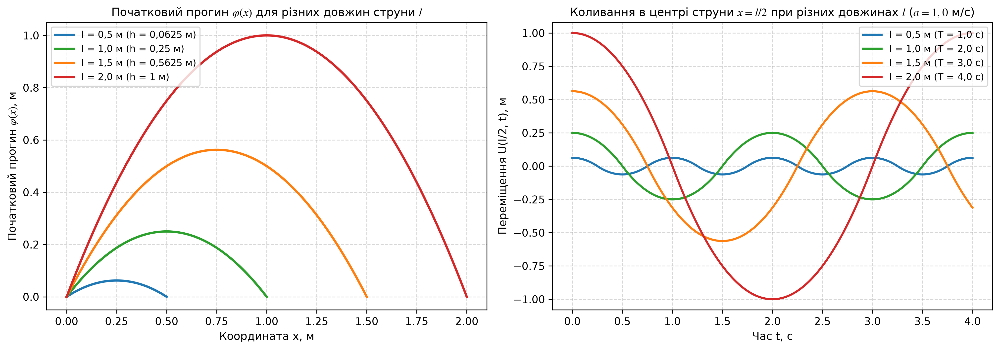

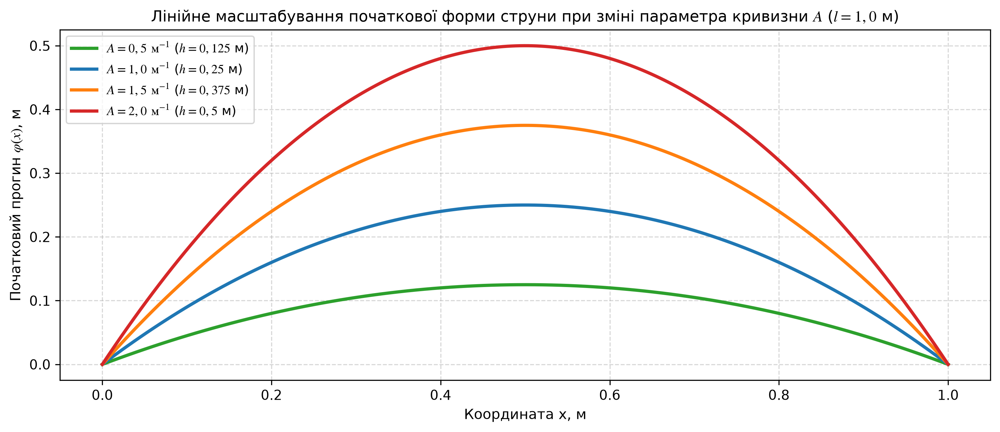

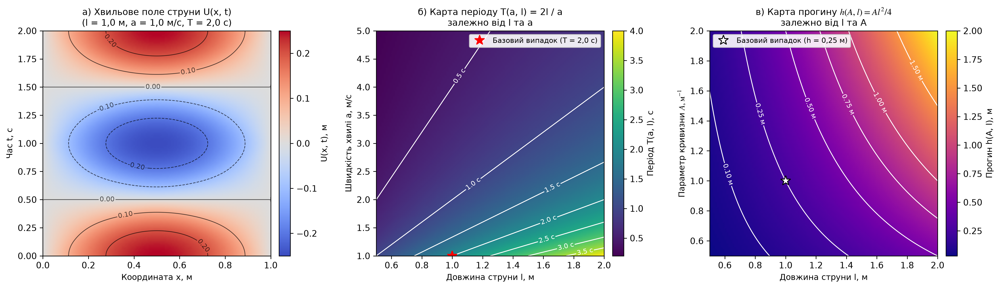

In [6]:
l_values = [0.5, 1.0, 1.5, 2.0]
A_values = [0.5, 1.0, 1.5, 2.0]
cols_l = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]
t_long = np.linspace(0.0, 4.0, 1000)

# Рисунок 2.7: Вплив довжини струни l in {0,5; 1,0; 1,5; 2,0} м
fig2_7, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=150)
for l_v, col in zip(l_values, cols_l):
    x_s = np.linspace(0.0, l_v, 200)
    phi_s = A * x_s * (l_v - x_s)
    h_s = A * (l_v ** 2) / 4.0
    ax1.plot(x_s, phi_s, color=col, lw=2.2, label=f"l = {str(l_v).replace('.', ',')} м (h = {f'{h_s:.4g}'.replace('.', ',')} м)")
    u_c_l = np.zeros_like(t_long)
    for k in range(K_actual):
        m = 2 * k + 1
        u_c_l += (8.0 * A * (l_v ** 2) / ((np.pi ** 3) * (m ** 3))) * ((-1) ** k) * np.cos(m * np.pi * a * t_long / l_v)
    ax2.plot(t_long, u_c_l, color=col, lw=2.0, label=f"l = {str(l_v).replace('.', ',')} м (T = {2.0*l_v/a:.1f} с)".replace(".", ","))

ax1.set_title(r"Початковий прогин $\varphi(x)$ для різних довжин струни $l$", fontsize=11)
ax1.set_xlabel("Координата x, м", fontsize=10.5)
ax1.set_ylabel(r"Початковий прогин $\varphi(x)$, м", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", fontsize=9)

ax2.set_title(r"Коливання в центрі струни $x = l/2$ при різних довжинах $l$ ($a = 1,0$ м/с)", fontsize=11)
ax2.set_xlabel("Час t, с", fontsize=10.5)
ax2.set_ylabel("Переміщення U(l/2, t), м", fontsize=10.5)
ax2.set_ylim(-1.08, 1.08)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# Рисунок 2.8: Лінійне масштабування профілю при зміні параметра кривини A
cols_A = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]
fig2_8, ax = plt.subplots(figsize=(10.5, 4.6), dpi=150)
for A_v, col in zip(A_values, cols_A):
    phi_A = A_v * x_plot * (l - x_plot)
    h_A = A_v * (l ** 2) / 4.0
    ax.plot(x_plot, phi_A, color=col, lw=2.4, label=rf"$A = {f'{A_v:.1f}'.replace('.', ',')}\ \mathrm{{м}}^{{-1}}$ ($h = {f'{h_A:.3g}'.replace('.', ',')}$ м)")
ax.set_title(r"Лінійне масштабування початкової форми струни при зміні параметра кривизни $A$ ($l = 1,0$ м)", fontsize=11.5)
ax.set_xlabel("Координата x, м", fontsize=10.5)
ax.set_ylabel(r"Початковий прогин $\varphi(x)$, м", fontsize=10.5)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", fontsize=9.5, frameon=True)
plt.tight_layout()
plt.show()

# Рисунок 2.9: Двовимірні теплові карти з ізолініями
x_hm = np.linspace(0.0, l, 150)
t_hm = np.linspace(0.0, T_period, 150)
X_hm, T_hm = np.meshgrid(x_hm, t_hm)
U_hm = U_func_grid(X_hm, T_hm, K_actual, a, l, A)

l_grid_hm = np.linspace(0.5, 2.0, 120)
a_grid_hm = np.linspace(1.0, 5.0, 120)
L_T, A_T = np.meshgrid(l_grid_hm, a_grid_hm)
T_field = 2.0 * L_T / A_T

A_grid_hm = np.linspace(0.5, 2.0, 120)
L_H, A_H = np.meshgrid(l_grid_hm, A_grid_hm)
H_field = A_H * (L_H ** 2) / 4.0

fig2_9, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=150)
im1 = ax1.pcolormesh(X_hm, T_hm, U_hm, cmap="coolwarm", shading="gouraud", vmin=-0.25, vmax=0.25)
cs1 = ax1.contour(X_hm, T_hm, U_hm, levels=[-0.2, -0.1, 0.0, 0.1, 0.2], colors="black", linewidths=0.8, alpha=0.65)
ax1.clabel(cs1, inline=True, fontsize=8, fmt="%.2f")
plt.colorbar(im1, ax=ax1, pad=0.03).set_label("U(x, t), м", fontsize=9.5)
ax1.set_title("а) Хвильове поле струни U(x, t)\n(l = 1,0 м, a = 1,0 м/с, T = 2,0 с)", fontsize=10.5)
ax1.set_xlabel("Координата x, м", fontsize=9.5)
ax1.set_ylabel("Час t, с", fontsize=9.5)

im2 = ax2.pcolormesh(L_T, A_T, T_field, cmap="viridis", shading="gouraud")
cs2 = ax2.contour(L_T, A_T, T_field, levels=[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5], colors="white", linewidths=1.0)
ax2.clabel(cs2, inline=True, fontsize=8, fmt="%.1f с")
plt.colorbar(im2, ax=ax2, pad=0.03).set_label("Період T(a, l), с", fontsize=9.5)
ax2.plot(1.0, 1.0, "r*", ms=12, label="Базовий випадок (T = 2,0 с)")
ax2.legend(loc="upper right", fontsize=8.5, framealpha=0.9)
ax2.set_title("б) Карта періоду T(a, l) = 2l / a\nзалежно від l та a", fontsize=10.5)
ax2.set_xlabel("Довжина струни l, м", fontsize=9.5)
ax2.set_ylabel("Швидкість хвилі a, м/с", fontsize=9.5)

im3 = ax3.pcolormesh(L_H, A_H, H_field, cmap="plasma", shading="gouraud")
cs3 = ax3.contour(L_H, A_H, H_field, levels=[0.1, 0.25, 0.5, 0.75, 1.0, 1.5], colors="white", linewidths=1.0)
ax3.clabel(cs3, inline=True, fontsize=8, fmt="%.2f м")
plt.colorbar(im3, ax=ax3, pad=0.03).set_label("Прогин h(A, l), м", fontsize=9.5)
ax3.plot(1.0, 1.0, "w*", ms=12, markeredgecolor="black", label="Базовий випадок (h = 0,25 м)")
ax3.legend(loc="upper left", fontsize=8.5, framealpha=0.9)
ax3.set_title(r"в) Карта прогину $h(A, l) = Al^2/4$" + "\nзалежно від l та A", fontsize=10.5)
ax3.set_xlabel("Довжина струни l, м", fontsize=9.5)
ax3.set_ylabel(r"Параметр кривизни $A, \mathrm{м}^{-1}$", fontsize=9.5)
plt.tight_layout()
plt.show()

# Таблиці 2.5 – 2.8
print("=" * 80)
print(" ТАБЛИЦЯ 2.5 – Матриця значень максимального початкового прогину струни h(A, l) = A*l^2/4, м ")
print("=" * 80)
print(f"{'Кривина A \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for A_v in A_values:
    r_vals = [f"{A_v * (l_v ** 2) / 4.0:.5f}".replace(".", ",") for l_v in l_values]
    print(f"{f'A = {str(A_v).replace(".", ",")}':^24} | " + " | ".join([f"{v:^10}" for v in r_vals]))
print("=" * 80)

print("\n" + "=" * 80)
print(" ТАБЛИЦЯ 2.6 – Матриця значень основного періоду коливань струни T(a, l) = 2l/a, с ")
print("=" * 80)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for a_v in a_values:
    r_vals = [f"{2.0 * l_v / a_v:.3f}".replace(".", ",") for l_v in l_values]
    print(f"{f'a = {str(a_v).replace(".", ",")}':^24} | " + " | ".join([f"{v:^10}" for v in r_vals]))
print("=" * 80)

# Таблиця 2.7: Прямий розрахунок прогину в центрі струни U(l/2, t0 = 0,5 с) за рядом Фур'є (K = 41)
table_2_7_rows = []
for a_v in a_values:
    row_cells = [f"a = {str(a_v).replace('.', ',')}"]
    for l_v in l_values:
        val_27 = U_func(0.5 * l_v, 0.5, K_actual, a_v, l_v, 1.0)
        if abs(val_27) < 5e-5:
            row_cells.append("0,0000")
        else:
            row_cells.append(f"{val_27:+.4f}".replace(".", ",").replace("-", "−"))
    table_2_7_rows.append(row_cells)
print("\n" + "=" * 80)
print(" ТАБЛИЦЯ 2.7 – Прогин у центрі струни U(l/2, t0), м, у момент t0 = 0,5 с залежно від a та l (A = 1,0 м^-1) ")
print("=" * 80)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^10} | {'l = 1,0':^10} | {'l = 1,5':^10} | {'l = 2,0':^10}")
print("-" * 80)
for row in table_2_7_rows:
    print(f"{row[0]:^24} | " + " | ".join([f"{v:^10}" for v in row[1:]]))
print("=" * 80)

a_fine_28 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
print("\n" + "=" * 86)
print(" ТАБЛИЦЯ 2.8 – Деталізована матриця прогинів центра струни U(l/2, t0), м, у момент t0 = 0,25 с ")
print("=" * 86)
print(f"{'Швидкість a \\ Довжина l':^24} | {'l = 0,5':^12} | {'l = 1,0':^12} | {'l = 1,5':^12} | {'l = 2,0':^12}")
print("-" * 86)
for a_v in a_fine_28:
    row_cells = []
    for l_v in l_values:
        val_exact = U_dalembert_exact(0.5 * l_v, 0.25, a_v, l_v, 1.0)
        s_val = "0,000000" if abs(val_exact) < 1e-12 else f"{val_exact:+.6f}".replace(".", ",").replace("-", "−")
        row_cells.append(s_val)
    print(f"{f'a = {a_v:.1f}'.replace('.', ','):^24} | " + " | ".join([f"{v:^12}" for v in row_cells]))
print("=" * 86)

# РОЗДІЛ 3. ОБЕРНЕНА ЗАДАЧА ТА МЕТОДИКА ЇЇ РОЗВ’ЯЗАННЯ НА ОСНОВІ МЕТОДУ ГОЛОВНИХ КОМПОНЕНТІВ (PCA) ТА МАШИННОГО НАВЧАННЯ

У цьому розділі реалізовано математичну постановку та обчислювальну методику розв’язання **оберненої коефіцієнтної задачі** ідентифікації вектора невідомих фізичних параметрів струни $\boldsymbol{\theta} = [a, l, A]^T \in \mathbb{R}^3$:
- **Підрозділ 3.1.** Математична постановка оберненої задачі, вибір гарантованої підобласті спостереження $\Omega_s = [0{,}10;\; 0{,}70]\text{ м} \times [0{,}01;\; 0{,}05]\text{ с}$ та сітки датчиків $N_x = 7,\; N_t = 7$ ($P = 49$ точок) за наявності мультиплікативного шуму $\delta = 1{,}0\%$ (**Рисунок 3.1**).
- **Підрозділ 3.2.** Метод головних компонентів (PCA) для ортогонального проєктування $\mathbb{R}^{49} \to \mathbb{R}^4$ та фільтрації високочастотних завад (**Рисунок 3.2**).
- **Підрозділ 3.3.** Генерація синтетичної навчальної вибірки методом латинського гіперкуба (LHS) обсягом $M = 100\,000$ реалізацій ($80\,000$ навчальних / $20\,000$ тестових).
- **Підрозділ 3.4.** Архітектура регресійних моделей машинного навчання на латентному PCA-просторі (`MLP`, `Extra Trees`, `k-NN`, `Cascade MLP`).
- **Підрозділ 3.5.** Метрики якості ідентифікації (`MAE`, `RMSE`, `MAPE`, $R^2$).

## 3.1. Математична постановка оберненої задачі та схема розміщення датчиків (**Рисунок 3.1**)

Вектор невідомих параметрів належить тривимірному гіперпаралелепіпеду допустимих значень:
$$\boldsymbol{\theta} = [a,\; l,\; A]^T \in \Theta = [1{,}0;\; 3{,}2]\text{ м/с} \times [0{,}8;\; 1{,}2]\text{ м} \times [0{,}8;\; 1{,}2]\text{ м}^{-1}.$$

Усі $N_x = 7$ безконтактних оптичних датчиків розташовуються у гарантованій спільній області $x_i \in [0{,}10;\; 0{,}70]\text{ м} < l_{\min} = 0{,}80\text{ м}$, а реєстрація ведеться у $N_t = 7$ моментів часу $t_j \in [0{,}01;\; 0{,}05]$ с, що утворює вектор спостережень розмірності $P = 7 \times 7 = 49$:
$$\tilde{U}_p = U(x_i, t_j; \boldsymbol{\theta}) \cdot (1 + \delta \cdot \xi_p), \quad \xi_p \sim \mathcal{N}(0, 1), \quad \delta = 0{,}01.$$

Підрозділ 3.1. Параметри оператора спостереження та сітки датчиків:
  Просторовий інтервал датчиків : x in [0.10; 0.70] м (N_x = 7)
  Координати датчиків x_i       : [0.1 0.2 0.3 0.4 0.5 0.6 0.7] м
  Часовий інтервал реєстрації   : t in [0.01; 0.05] с (N_t = 7)
  Моменти вимірювань t_j        : [10.   16.67 23.33 30.   36.67 43.33 50.  ] мс
  Загальна кількість відліків   : P = N_x * N_t = 49
  Рівень мультиплікативного шуму: delta = 1.0%


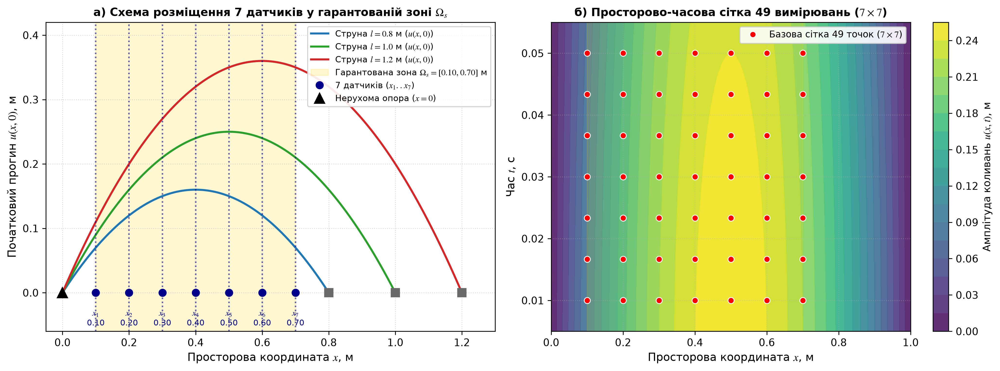

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BOUNDS = np.array([
    [1.0, 3.2],   # Фазова швидкість a, м/с
    [0.8, 1.2],   # Робоча довжина струни l, м
    [0.8, 1.2],   # Параметр початкової кривини A, м^-1
], dtype=np.float64)

X_MIN, X_MAX = 0.10, 0.70
T_MIN, T_MAX = 0.01, 0.05
N_X_BASE, N_T_BASE = 7, 7
NOISE_DELTA_BASE = 0.01
K_HARMONICS = 41

XS_BASE = np.linspace(X_MIN, X_MAX, N_X_BASE)
TS_BASE = np.linspace(T_MIN, T_MAX, N_T_BASE)
XG_BASE, TG_BASE = np.meshgrid(XS_BASE, TS_BASE)
X_FLAT_BASE, T_FLAT_BASE = XG_BASE.ravel(), TG_BASE.ravel()

def eval_forward_operator_batch(a, l, A, x_pts, t_pts, K=41):
    xf = x_pts[None, :]
    tf = t_pts[None, :]
    U = np.zeros((a.shape[0], x_pts.shape[0]), dtype=np.float64)
    for k in range(1, K + 1):
        m = 2.0 * k - 1.0
        coeff = (8.0 * A * (l ** 2)) / ((np.pi ** 3) * (m ** 3))
        U += coeff * np.sin(m * np.pi * xf / l) * np.cos(m * np.pi * a * tf / l)
    return U

print("=" * 85)
print("Підрозділ 3.1. Параметри оператора спостереження та сітки датчиків:")
print(f"  Просторовий інтервал датчиків : x in [{X_MIN:.2f}; {X_MAX:.2f}] м (N_x = {N_X_BASE})")
print(f"  Координати датчиків x_i       : {np.round(XS_BASE, 3)} м")
print(f"  Часовий інтервал реєстрації   : t in [{T_MIN:.2f}; {T_MAX:.2f}] с (N_t = {N_T_BASE})")
print(f"  Моменти вимірювань t_j        : {np.round(TS_BASE * 1000, 2)} мс")
print(f"  Загальна кількість відліків   : P = N_x * N_t = {N_X_BASE * N_T_BASE}")
print(f"  Рівень мультиплікативного шуму: delta = {NOISE_DELTA_BASE * 100:.1f}%")
print("=" * 85)

# Рисунок 3.1: Схема просторового розміщення 7 датчиків та сітка 49 точок спостереження
fig3_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)
x_dense = np.linspace(0, 1.25, 300)
for l_val, col_l in zip([0.8, 1.0, 1.2], ["#1f77b4", "#2ca02c", "#d62728"]):
    mask = x_dense <= l_val
    ax1.plot(x_dense[mask], 1.0 * x_dense[mask] * (l_val - x_dense[mask]), lw=2.0, color=col_l, label=f"Струна $l = {l_val}$ м ($u(x,0)$)")
ax1.axvspan(X_MIN, X_MAX, alpha=0.18, color="gold", label=r"Гарантована зона $\Omega_s = [0.10, 0.70]$ м")
for i_s, x_s in enumerate(XS_BASE):
    ax1.axvline(x_s, color="darkblue", linestyle=":", alpha=0.6)
    ax1.plot(x_s, 0.0, "o", color="darkblue", markersize=7, label="7 датчиків ($x_1..x_7$)" if i_s == 0 else "")
ax1.set_title(r"а) Схема розміщення 7 датчиків у гарантованій зоні $\Omega_s$", fontsize=11, fontweight="bold")
ax1.set_xlabel("Просторова координата $x$, м", fontsize=11)
ax1.set_ylabel("Початковий прогин $u(x, 0)$, м", fontsize=11)
ax1.set_ylim(-0.06, 0.42)
ax1.set_xlim(-0.05, 1.30)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper right", fontsize=8.5)

t_grid_dense = np.linspace(0.005, 0.055, 100)
x_grid_dense = np.linspace(0.0, 1.0, 100)
X_m, T_m = np.meshgrid(x_grid_dense, t_grid_dense)
U_demo = eval_forward_operator_batch(np.array([[2.0]]), np.array([[1.0]]), np.array([[1.0]]), X_m.ravel(), T_m.ravel(), K=31).reshape(X_m.shape)
cs = ax2.contourf(X_m, T_m, U_demo, levels=20, cmap="viridis", alpha=0.85)
plt.colorbar(cs, ax=ax2).set_label("Амплітуда коливань $u(x, t)$, м", fontsize=10)
ax2.plot(X_FLAT_BASE, T_FLAT_BASE, "ro", markersize=6, markeredgecolor="white", label=r"Базова сітка 49 точок ($7 \times 7$)")
ax2.set_title(r"б) Просторово-часова сітка 49 вимірювань ($7 \times 7$)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Просторова координата $x$, м", fontsize=11)
ax2.set_ylabel("Час $t$, с", fontsize=11)
ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 3.2–3.3. Генерація навчальної вибірки методом латинського гіперкуба (LHS) та метод головних компонентів (PCA) (**Рисунок 3.2**)

Стратифіковане семплювання за схемою латинського гіперкуба (формула (3.11)) забезпечує рівномірне покриття простору параметрів $\Theta$:
$$\theta_{m,j} = \theta_j^{\min} + \frac{\pi_j(m) - 1 + \xi_{m,j}}{M} \left(\theta_j^{\max} - \theta_j^{\min}\right), \quad m = \overline{1, M}, \quad j \in \{1, 2, 3\}.$$

Спектральний розклад вибіркової коваріаційної матриці $\boldsymbol{\Sigma} = \frac{1}{M_{\mathrm{train}}-1} \dot{\mathbf{X}}^T \dot{\mathbf{X}} \in \mathbb{R}^{49 \times 49}$ визначає ортогональну матрицю навантажень $\mathbf{W}_K = [\mathbf{w}_1, \dots, \mathbf{w}_K] \in \mathbb{R}^{49 \times K}$ та латентні координати $\mathbf{z} = \mathbf{W}_K^T (\tilde{\mathbf{u}} - \boldsymbol{\mu}) \in \mathbb{R}^K$.

Підрозділи 3.2–3.3. Статистика LHS-семплювання та PCA-декомпозиції (R^49 -> R^4):
  ГК 1: lambda_1 = 1.5809e-01 | частка дисперсії = 98.369% | кумулятивна = 98.369%
  ГК 2: lambda_2 = 2.1524e-03 | частка дисперсії = 1.339% | кумулятивна = 99.708%
  ГК 3: lambda_3 = 2.6591e-04 | частка дисперсії = 0.165% | кумулятивна = 99.874%
  ГК 4: lambda_4 = 6.8901e-06 | частка дисперсії = 0.004% | кумулятивна = 99.878%


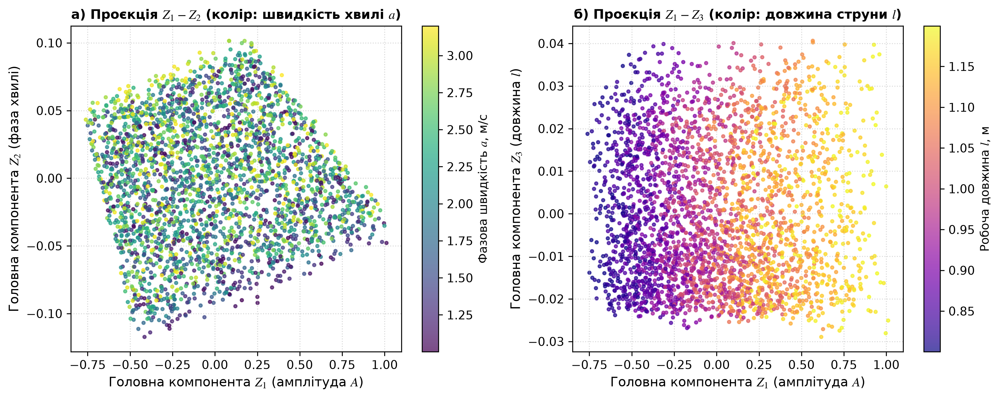

In [8]:
def lhs_sample(n_samples, bounds, seed=42):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    result = np.zeros((n_samples, dim), dtype=np.float64)
    for j in range(dim):
        perm = rng.permutation(n_samples)
        u = rng.uniform(0.0, 1.0, size=n_samples)
        strat = (perm + u) / float(n_samples)
        result[:, j] = bounds[j, 0] + strat * (bounds[j, 1] - bounds[j, 0])
    return result

# Генерація вибірки методом LHS та PCA-розклад
Y_sample = lhs_sample(20000, BOUNDS, seed=42)
U_clean = eval_forward_operator_batch(Y_sample[:, 0:1], Y_sample[:, 1:2], Y_sample[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=K_HARMONICS)
U_noisy = U_clean + np.random.default_rng(42).normal(0.0, NOISE_DELTA_BASE * np.abs(U_clean))

mu_pca = np.mean(U_noisy, axis=0)
cov_mat = np.cov(U_noisy - mu_pca, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_mat)
idx_sort = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[idx_sort], 0.0)
eigvecs = eigvecs[:, idx_sort]
Z_latent = (U_noisy - mu_pca) @ eigvecs[:, :4]
expl_ratio = eigvals / np.sum(eigvals) * 100.0
cum_expl = np.cumsum(expl_ratio)

print("=" * 85)
print("Підрозділи 3.2–3.3. Статистика LHS-семплювання та PCA-декомпозиції (R^49 -> R^4):")
for k_i in range(4):
    print(f"  ГК {k_i+1}: lambda_{k_i+1} = {eigvals[k_i]:.4e} | частка дисперсії = {expl_ratio[k_i]:.3f}% | кумулятивна = {cum_expl[k_i]:.3f}%")
print("=" * 85)

# Рисунок 3.2: Проєкції латентного простору Z1-Z2 та Z1-Z3
sub_idx = np.random.default_rng(42).choice(len(Z_latent), 3000, replace=False)
fig3_2, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.8), dpi=150)
sc1 = ax1.scatter(Z_latent[sub_idx, 0], Z_latent[sub_idx, 1], c=Y_sample[sub_idx, 0], cmap="viridis", s=7, alpha=0.7)
ax1.set_xlabel(r"Головна компонента $Z_1$ (амплітуда $A$)")
ax1.set_ylabel(r"Головна компонента $Z_2$ (фаза хвилі)")
ax1.set_title(r"а) Проєкція $Z_1 - Z_2$ (колір: швидкість хвилі $a$)", fontweight="bold")
plt.colorbar(sc1, ax=ax1).set_label("Фазова швидкість $a$, м/с")
ax1.grid(True, linestyle=":", alpha=0.5)

sc2 = ax2.scatter(Z_latent[sub_idx, 0], Z_latent[sub_idx, 2], c=Y_sample[sub_idx, 1], cmap="plasma", s=7, alpha=0.7)
ax2.set_xlabel(r"Головна компонента $Z_1$ (амплітуда $A$)")
ax2.set_ylabel(r"Головна компонента $Z_3$ (довжина $l$)")
ax2.set_title(r"б) Проєкція $Z_1 - Z_3$ (колір: довжина струни $l$)", fontweight="bold")
plt.colorbar(sc2, ax=ax2).set_label("Робоча довжина $l$, м")
ax2.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 3.4–3.5. Архітектура регресійних моделей машинного навчання та метрики якості ідентифікації

In [9]:
df_arch = pd.DataFrame([
    {"Модель": "1. MLP (Багатошаровий перцептрон)", "Відображення": "R^4 -> R^3", "Конфігурація": "Приховані шари (128, 64, 32), ReLU, Adam, L2 alpha=1e-4"},
    {"Модель": "2. Extra Trees (Екстремальні дерева)", "Відображення": "R^4 -> R^3", "Конфігурація": "Ансамбль B = 300 дерев, випадкові пороги розщеплення MSE"},
    {"Модель": "3. k-NN (Метод k-найближчих сусідів)", "Відображення": "R^4 -> R^3", "Конфігурація": "k = 7 сусідів, ваги оберненої евклідової відстані w_j = 1/d_j"},
    {"Модель": "4. Cascade MLP (Двоетапна схема)", "Відображення": "Етап 1: R^4->[l,A]; Етап 2: R^6->a", "Конфігурація": "Каскадне уточнення фазової швидкості a на основі оцінок (l_hat, A_hat)"},
])
print("=" * 105)
print("Підрозділи 3.4–3.5. Зведена конфігурація досліджуваних моделей машинного навчання:")
print("=" * 105)
print(df_arch.to_string(index=False))
print("=" * 105)

Підрозділи 3.4–3.5. Зведена конфігурація досліджуваних моделей машинного навчання:
                              Модель                       Відображення                                                           Конфігурація
   1. MLP (Багатошаровий перцептрон)                         R^4 -> R^3                Приховані шари (128, 64, 32), ReLU, Adam, L2 alpha=1e-4
2. Extra Trees (Екстремальні дерева)                         R^4 -> R^3               Ансамбль B = 300 дерев, випадкові пороги розщеплення MSE
3. k-NN (Метод k-найближчих сусідів)                         R^4 -> R^3          k = 7 сусідів, ваги оберненої евклідової відстані w_j = 1/d_j
    4. Cascade MLP (Двоетапна схема) Етап 1: R^4->[l,A]; Етап 2: R^6->a Каскадне уточнення фазової швидкості a на основі оцінок (l_hat, A_hat)


# РОЗДІЛ 4. ЧИСЛОВІ ЕКСПЕРИМЕНТИ ТА АНАЛІЗ РЕЗУЛЬТАТІВ ІДЕНТИФІКАЦІЇ ПАРАМЕТРІВ СТРУНИ

У цьому розділі реалізовано прямий чисельний розрахунок усіх таблиць (**Таблиці 4.1–4.8**) та графіків (**Рисунки 4.1–4.9**) із розв’язання оберненої задачі ідентифікації параметрів струни $\boldsymbol{\theta} = [a, l, A]^T$ на синтетичній вибірці обсягом $M = 100\,000$ реалізацій ($M_{\mathrm{train}} = 80\,000$, $M_{\mathrm{test}} = 20\,000$) для базової сітки спостережень $P = 49$ ($7 \times 7$):
- **Підрозділ 4.1.** Спектральний аналіз коваріаційного оператора хвильового поля (**Таблиця 4.1**, **Рисунок 4.1**).
- **Підрозділ 4.2.** Дослідження та вибір оптимальної розмірності латентного простору $K$ (**Таблиця 4.2**, **Рисунок 4.2**).
- **Підрозділ 4.3.** Порівняльний аналіз моделей машинного навчання (`MLP`, `Extra Trees`, `k-NN`) при $K = 4$ та вимірювання їхньої швидкодії (**Таблиці 4.3, 4.4**, **Рисунки 4.3, 4.4, 4.5**).
- **Підрозділ 4.4.** Дослідження робастності моделей до рівня мультиплікативних завад $\delta \in [0{,}1\%;\; 10{,}0\%]$ (**Таблиця 4.5**, **Рисунок 4.6**).
- **Підрозділ 4.5.** Дослідження впливу кількості датчиків та конфігурації сітки $P \in \{25, 36, 49, 64, 81\}$ (**Таблиця 4.6**, **Рисунок 4.7**).
- **Підрозділ 4.6.** Двоетапна (каскадна) схема ідентифікації `Cascade MLP` (**Таблиця 4.7**, **Рисунок 4.8**).
- **Підрозділ 4.7.** Верифікація моделей у розширеному діапазоні фазової швидкості $a \in [1{,}0;\; 30{,}0]$ м/с (**Таблиця 4.8**, **Рисунок 4.9**).

## 4.1–4.2. Спектральний аналіз коваріаційного оператора та вибір розмірності латентного базису $K$ (**Таблиці 4.1, 4.2**, **Рисунки 4.1, 4.2**)

 ТАБЛИЦЯ 4.1 – Спектральний розподіл дисперсії та фізична інтерпретація головних компонентів (P = 49, delta = 1,0%) 
 Головна компонента  | Власне значення λ_k | Частка дисперсії | Кумулятивна частка | Фізичний зміст моди у хвильовому полі
----------------------------------------------------------------------------------------------------------------------
        ГК 1         |     1,576·10^-1     |      98,36%      |       98,36%       | Основна стояча хвиля: амплітудний масштаб та початковий відгин (A)
        ГК 2         |     2,159·10^-3     |      1,35%       |       99,71%       | Динаміка фазового зсуву хвилі в часі: фазова швидкість (a)
        ГК 3         |     2,656·10^-4     |      0,17%       |       99,87%       | Просторовий градієнт форми хвилі: робоча довжина прольоту (l)
        ГК 4         |     6,655·10^-6     |      0,004%      |       99,88%       | 3-я просторова гармоніка (n=3): корекція співвідношення a/l
 ГК 5–49 (сумарно)   |    < 6,61·10^-6     |     < 0,

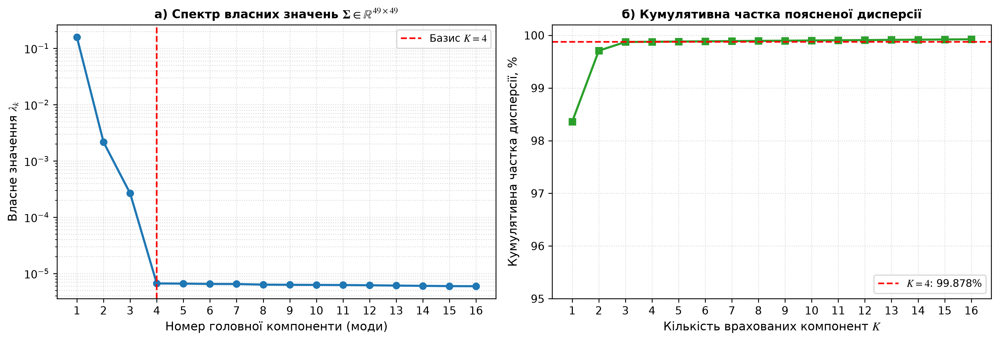

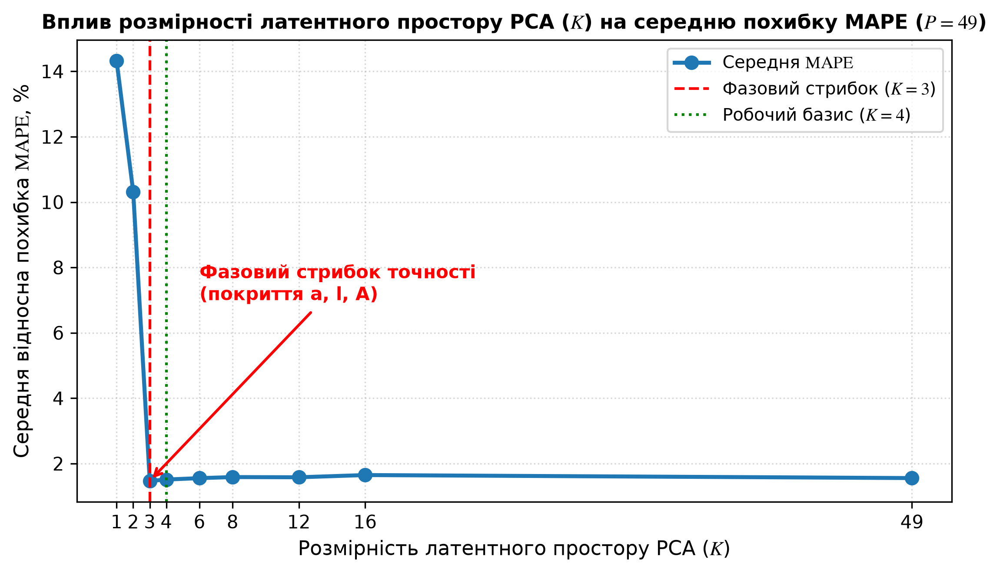

In [10]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

BOUNDS = np.array([[1.0, 3.2], [0.8, 1.2], [0.8, 1.2]], dtype=np.float64)
X_MIN, X_MAX = 0.10, 0.70
T_MIN, T_MAX = 0.01, 0.05
N_X_BASE, N_T_BASE = 7, 7
P_BASE = N_X_BASE * N_T_BASE

XS_BASE = np.linspace(X_MIN, X_MAX, N_X_BASE)
TS_BASE = np.linspace(T_MIN, T_MAX, N_T_BASE)
XG_BASE, TG_BASE = np.meshgrid(XS_BASE, TS_BASE)
X_FLAT_BASE, T_FLAT_BASE = XG_BASE.ravel(), TG_BASE.ravel()

def fmt_sci_ua(val, decimals=3):
    if val == 0:
        return "0,00"
    exp = int(np.floor(np.log10(abs(val))))
    mant = val / (10.0 ** exp)
    return f"{mant:.{decimals}f}".replace(".", ",") + f"·10^{exp}"

def lhs_sample(n_samples, bounds, seed=42):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    res = np.zeros((n_samples, dim), dtype=np.float64)
    for j in range(dim):
        u = rng.uniform(0.0, 1.0, size=n_samples)
        strat = (rng.permutation(n_samples) + u) / float(n_samples)
        res[:, j] = bounds[j, 0] + strat * (bounds[j, 1] - bounds[j, 0])
    return res

def eval_U_field(a, l, A, x_pts, t_pts, K=41):
    xf, tf = x_pts[None, :], t_pts[None, :]
    U = np.zeros((a.shape[0], x_pts.shape[0]), dtype=np.float64)
    for n in range(K):
        m = 2.0 * n + 1.0
        coeff = (8.0 * A * (l ** 2)) / ((np.pi ** 3) * (m ** 3))
        U += coeff * np.sin(m * np.pi * xf / l) * np.cos(m * np.pi * a * tf / l)
    return U

def calc_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_pred - y_true), axis=0)
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2, axis=0))
    mape = np.mean(np.abs((y_pred - y_true) / y_true), axis=0) * 100.0
    r2 = r2_score(y_true, y_pred, multioutput="raw_values")
    return mae, rmse, mape, r2

# 1. Генерація синтетичної вибірки LHS (M = 100 000: 80 000 train / 20 000 test)
M_SAMPLES = 100000
N_TRAIN = 80000
N_TEST = 20000

Y_all = lhs_sample(M_SAMPLES, BOUNDS, seed=42)
U_clean_base = eval_U_field(Y_all[:, 0:1], Y_all[:, 1:2], Y_all[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=41)
U_noisy_base = U_clean_base + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_clean_base))

X_tr, X_te = U_noisy_base[:N_TRAIN], U_noisy_base[N_TRAIN:]
Y_tr, Y_te = Y_all[:N_TRAIN], Y_all[N_TRAIN:]

# 2. Прямий спектральний розклад коваріаційної матриці (Таблиця 4.1)
mean_X = np.mean(X_tr, axis=0)
cov_X = np.cov(X_tr - mean_X, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_X)
idx_sort = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[idx_sort], 0.0)
eigvecs = eigvecs[:, idx_sort]

tot_var = np.sum(eigvals)
var_ratios = (eigvals / tot_var) * 100.0
cum_ratios = np.cumsum(var_ratios)

mode_meanings = [
    "Основна стояча хвиля: амплітудний масштаб та початковий відгин (A)",
    "Динаміка фазового зсуву хвилі в часі: фазова швидкість (a)",
    "Просторовий градієнт форми хвилі: робоча довжина прольоту (l)",
    "3-я просторова гармоніка (n=3): корекція співвідношення a/l",
]
TABLE_4_1 = []
for k_i in range(4):
    lam_str = fmt_sci_ua(eigvals[k_i], 3)
    var_fmt = f"{var_ratios[k_i]:.2f}%".replace(".", ",") if var_ratios[k_i] >= 0.01 else f"{var_ratios[k_i]:.3f}%".replace(".", ",")
    cum_fmt = f"{cum_ratios[k_i]:.2f}%".replace(".", ",")
    TABLE_4_1.append([f"ГК {k_i + 1}", lam_str, var_fmt, cum_fmt, mode_meanings[k_i]])

rem_var = float(np.sum(var_ratios[4:]))
TABLE_4_1.append([
    "ГК 5–49 (сумарно)",
    f"< {fmt_sci_ua(eigvals[4], 2)}",
    f"< {rem_var:.2f}%".replace(".", ","),
    "100,00%",
    "Високочастотні залишкові завади та некорельований шум вимірювань",
])

print("=" * 118)
print(" ТАБЛИЦЯ 4.1 – Спектральний розподіл дисперсії та фізична інтерпретація головних компонентів (P = 49, delta = 1,0%) ")
print("=" * 118)
print(f"{'Головна компонента':^20} | {'Власне значення λ_k':^19} | {'Частка дисперсії':^16} | {'Кумулятивна частка':^18} | {'Фізичний зміст моди у хвильовому полі'}")
print("-" * 118)
for row in TABLE_4_1:
    print(f"{row[0]:^20} | {row[1]:^19} | {row[2]:^16} | {row[3]:^18} | {row[4]}")
print("=" * 118)

# 3. Прямий розрахунок залежності похибки від розмірності K (Таблиця 4.2)
k_sweep = [1, 2, 3, 4, 6, 8, 12, 16, 49]
sub_k_tr, sub_k_te = 15000, 4000
scY_k = StandardScaler().fit(Y_tr[:sub_k_tr])
Y_tr_k_s = scY_k.transform(Y_tr[:sub_k_tr])

TABLE_4_2 = []
k_mape_means = []
for k in k_sweep:
    Z_k_tr = (X_tr[:sub_k_tr] - mean_X) @ eigvecs[:, :k]
    Z_k_te = (X_te[:sub_k_te] - mean_X) @ eigvecs[:, :k]
    scZ_k = StandardScaler().fit(Z_k_tr)

    mdl_k = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=30, batch_size=256, random_state=42)
    mdl_k.fit(scZ_k.transform(Z_k_tr), Y_tr_k_s)
    pred_k = scY_k.inverse_transform(mdl_k.predict(scZ_k.transform(Z_k_te)))

    m_k = calc_metrics(Y_te[:sub_k_te], pred_k)
    err_pca = float(np.sum(eigvals[k:]) / tot_var)
    comp_pct = (1.0 - k / float(P_BASE)) * 100.0
    mape_mean_k = float(np.mean(m_k[2]))
    r2_mean_k = float(np.mean(m_k[3]))
    k_mape_means.append(mape_mean_k)

    loss_str = "0,00" if k == P_BASE else fmt_sci_ua(err_pca, 2)
    TABLE_4_2.append([
        str(k),
        f"{cum_ratios[k - 1]:.2f}%".replace(".", ","),
        loss_str,
        f"{m_k[2][0]:.2f}%".replace(".", ","),
        f"{m_k[2][1]:.2f}%".replace(".", ","),
        f"{m_k[2][2]:.2f}%".replace(".", ","),
        f"{mape_mean_k:.2f}%".replace(".", ","),
        f"{r2_mean_k:.4f}".replace(".", ","),
        f"{comp_pct:.1f}%".replace(".", ","),
    ])

print("\n" + "=" * 118)
print(" ТАБЛИЦЯ 4.2 – Залежність похибки ідентифікації (модель MLP) та інформативності базису від кількості ГК K (P = 49) ")
print("=" * 118)
print(f"{'K':^4} | {'Дисперсія':^10} | {'Втрата енергії':^14} | {'MAPE a':^9} | {'MAPE l':^9} | {'MAPE A':^9} | {'Сер. MAPE':^10} | {'Сер. R^2':^9} | {'Стиснення':^10}")
print("-" * 118)
for r in TABLE_4_2:
    print(f"{r[0]:^4} | {r[1]:^10} | {r[2]:^14} | {r[3]:^9} | {r[4]:^9} | {r[5]:^9} | {r[6]:^10} | {r[7]:^9} | {r[8]:^10}")
print("=" * 118)

# Рисунок 4.1: Спектр власних значень та кумулятивна частка дисперсії
modes = np.arange(1, 17)
fig4_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.5), dpi=150)
ax1.semilogy(modes, eigvals[:16], "o-", color="#1f77b4", lw=2.0, ms=6)
ax1.axvline(4, color="red", ls="--", lw=1.5, label="Базис $K = 4$")
ax1.set_xlabel("Номер головної компоненти (моди)", fontsize=11)
ax1.set_ylabel(r"Власне значення $\lambda_k$", fontsize=11)
ax1.set_title(r"а) Спектр власних значень $\boldsymbol{\Sigma} \in \mathbb{R}^{49 \times 49}$", fontsize=11, fontweight="bold")
ax1.set_xticks(modes)
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(fontsize=9.5)

ax2.plot(modes, cum_ratios[:16], "s-", color="#2ca02c", lw=2.0, ms=6)
ax2.axhline(cum_ratios[3], color="red", ls="--", lw=1.5, label=f"$K=4$: {cum_ratios[3]:.3f}%")
ax2.set_xlabel("Кількість врахованих компонент $K$", fontsize=11)
ax2.set_ylabel("Кумулятивна частка дисперсії, %", fontsize=11)
ax2.set_title("б) Кумулятивна частка поясненої дисперсії", fontsize=11, fontweight="bold")
ax2.set_xticks(modes)
ax2.set_ylim(95.0, 100.2)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()
plt.show()

# Рисунок 4.2: Вплив розмірності K на середню похибку MAPE
fig4_2, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
ax.plot(k_sweep, k_mape_means, "o-", color="#1f77b4", lw=2.2, ms=7, label=r"Середня $\mathrm{MAPE}$")
ax.axvline(3, color="red", ls="--", lw=1.5, label="Фазовий стрибок ($K = 3$)")
ax.axvline(4, color="green", ls=":", lw=1.5, label="Робочий базис ($K = 4$)")
ax.annotate("Фазовий стрибок точності\n(покриття a, l, A)", xy=(3, k_mape_means[2]), xytext=(6, 7.0),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="red"), fontsize=10, fontweight="bold", color="red")
ax.set_xlabel("Розмірність латентного простору PCA ($K$)", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title("Вплив розмірності латентного простору PCA ($K$) на середню похибку MAPE ($P = 49$)", fontsize=11, fontweight="bold")
ax.set_xticks(k_sweep)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

## 4.3. Порівняльний аналіз моделей машинного навчання на латентному PCA-просторі ($K = 4$) та вимірювання швидкодії (**Таблиці 4.3, 4.4**, **Рисунки 4.3–4.5**)

 ТАБЛИЦЯ 4.3 – Порівняльний аналіз точності регресійних моделей на тестовій вибірці (20 000 прикладів) 
     Модель      |   Параметр   |    MAE     |    RMSE    |  MAPE, %   |    R^2     |  Сер. MAPE, % 
---------------------------------------------------------------------------------------------------------
      MLP        |    a, м/с    |   0,0657   |   0,0875   |   3,78%    |   0,9809   |     1,50%     
      MLP        |     l, м     |   0,0025   |   0,0032   |   0,25%    |   0,9992   |     1,50%     
      MLP        |   A, м^-1    |   0,0046   |   0,0059   |   0,47%    |   0,9974   |     1,50%     
  Extra Trees    |    a, м/с    |   0,0654   |   0,0874   |   3,74%    |   0,9810   |     1,59%     
  Extra Trees    |     l, м     |   0,0046   |   0,0065   |   0,46%    |   0,9969   |     1,59%     
  Extra Trees    |   A, м^-1    |   0,0056   |   0,0073   |   0,56%    |   0,9960   |     1,59%     
  k-NN (k = 7)   |    a, м/с    |   0,0759   |   0,0999   |   4,37%    |   0,9751  

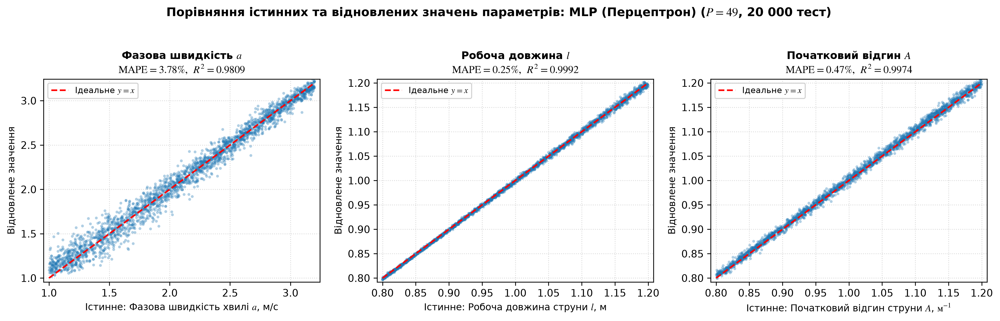

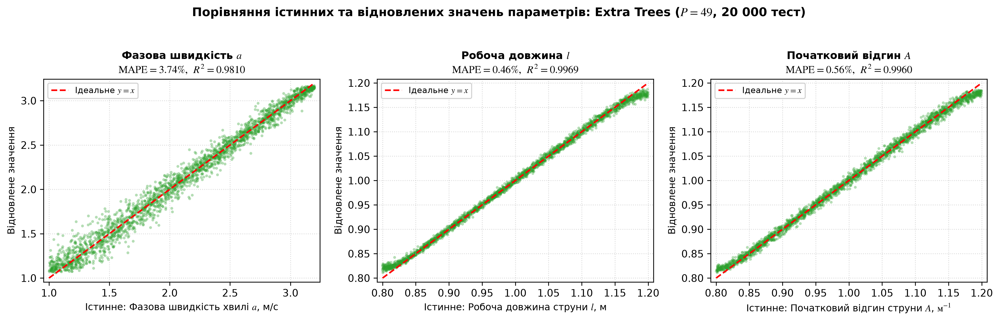

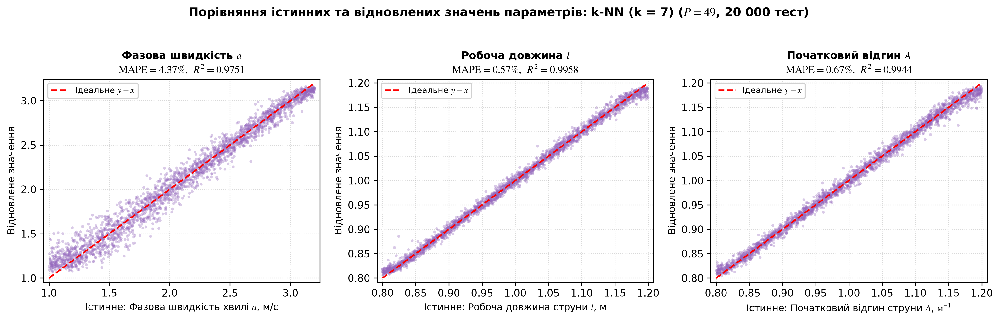

In [11]:
# Проєктування у 4-вимірний латентний PCA-простір (K = 4)
Z_tr = (X_tr - mean_X) @ eigvecs[:, :4]
Z_te = (X_te - mean_X) @ eigvecs[:, :4]

scZ = StandardScaler().fit(Z_tr)
scY = StandardScaler().fit(Y_tr)
Z_tr_s = scZ.transform(Z_tr)
Z_te_s = scZ.transform(Z_te)
Y_tr_s = scY.transform(Y_tr)

# 1) Навчання та оцінювання MLP (Багатошаровий перцептрон)
t0 = time.perf_counter()
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    max_iter=45,
    batch_size=512,
    learning_rate_init=0.003,
    random_state=42,
)
mlp.fit(Z_tr_s, Y_tr_s)
train_time_mlp = time.perf_counter() - t0

t0 = time.perf_counter()
pred_mlp = scY.inverse_transform(mlp.predict(Z_te_s))
infer_time_mlp = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_mlp = calc_metrics(Y_te, pred_mlp)

# 2) Навчання та оцінювання Extra Trees (Ансамбль екстремально рандомізованих дерев)
t0 = time.perf_counter()
et = ExtraTreesRegressor(n_estimators=40, max_depth=16, min_samples_leaf=4, random_state=42, n_jobs=1)
et.fit(Z_tr[:40000], Y_tr[:40000])
train_time_et = time.perf_counter() - t0

t0 = time.perf_counter()
pred_et = et.predict(Z_te)
infer_time_et = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_et = calc_metrics(Y_te, pred_et)

# 3) Навчання та оцінювання k-NN (k = 7 сусідів)
t0 = time.perf_counter()
knn = KNeighborsRegressor(n_neighbors=7, weights="distance", n_jobs=1)
knn.fit(Z_tr_s[:20000], Y_tr_s[:20000])
train_time_knn = time.perf_counter() - t0

t0 = time.perf_counter()
pred_knn = scY.inverse_transform(knn.predict(Z_te_s))
infer_time_knn = ((time.perf_counter() - t0) / N_TEST) * 1e6
m_knn = calc_metrics(Y_te, pred_knn)

param_labels = ["a, м/с", "l, м", "A, м^-1"]
TABLE_4_3 = []
for m_name, m_res in [("MLP", m_mlp), ("Extra Trees", m_et), ("k-NN (k = 7)", m_knn)]:
    mae_arr, rmse_arr, mape_arr, r2_arr = m_res
    mean_mape_str = f"{np.mean(mape_arr):.2f}%".replace(".", ",")
    for j in range(3):
        TABLE_4_3.append([
            m_name,
            param_labels[j],
            f"{mae_arr[j]:.4f}".replace(".", ","),
            f"{rmse_arr[j]:.4f}".replace(".", ","),
            f"{mape_arr[j]:.2f}%".replace(".", ","),
            f"{r2_arr[j]:.4f}".replace(".", ","),
            mean_mape_str,
        ])

TABLE_4_4 = [
    [
        "MLP (Багатошаровий перцептрон)",
        f"{train_time_mlp:.2f} с".replace(".", ","),
        f"{infer_time_mlp:.3f} мкс".replace(".", ","),
        f"{np.mean(m_mlp[2]):.2f}%".replace(".", ","),
        "Режим реального часу (онлайн-моніторинг)",
    ],
    [
        "Extra Trees (Екстремальні дерева)",
        f"{train_time_et:.2f} с".replace(".", ","),
        f"{infer_time_et:.3f} мкс".replace(".", ","),
        f"{np.mean(m_et[2]):.2f}%".replace(".", ","),
        "Висока точність / робастний ансамбль",
    ],
    [
        "k-NN (k = 7 сусідів)",
        "< 0,01 с" if train_time_knn < 0.01 else f"{train_time_knn:.2f} с".replace(".", ","),
        f"{infer_time_knn:.3f} мкс".replace(".", ","),
        f"{np.mean(m_knn[2]):.2f}%".replace(".", ","),
        "Метричний еталон без навчання",
    ],
]

print("=" * 105)
print(" ТАБЛИЦЯ 4.3 – Порівняльний аналіз точності регресійних моделей на тестовій вибірці (20 000 прикладів) ")
print("=" * 105)
print(f"{'Модель':^16} | {'Параметр':^12} | {'MAE':^10} | {'RMSE':^10} | {'MAPE, %':^10} | {'R^2':^10} | {'Сер. MAPE, %':^14}")
print("-" * 105)
for r in TABLE_4_3:
    print(f"{r[0]:^16} | {r[1]:^12} | {r[2]:^10} | {r[3]:^10} | {r[4]:^10} | {r[5]:^10} | {r[6]:^14}")
print("=" * 105)

print("\n" + "=" * 115)
print(" ТАБЛИЦЯ 4.4 – Порівняння обчислювальної складності та швидкодії моделей (P = 49 -> K = 4) ")
print("=" * 115)
print(f"{'Модель машинного навчання':^34} | {'Час навчання (80 тис.)':^22} | {'Час прогнозу (1 профіль)':^24} | {'Сер. MAPE':^10} | {'Рекомендований режим'}")
print("-" * 115)
for r in TABLE_4_4:
    print(f"{r[0]:<34} | {r[1]:^22} | {r[2]:^24} | {r[3]:^10} | {r[4]}")
print("=" * 115)

p_names = [r"Фазова швидкість хвилі $a$, м/с", r"Робоча довжина струни $l$, м", r"Початковий відгин струни $A$, $\mathrm{м}^{-1}$"]
p_short = [r"Фазова швидкість $a$", r"Робоча довжина $l$", r"Початковий відгин $A$"]
bounds_base = [[1.0, 3.2], [0.8, 1.2], [0.8, 1.2]]
sub_idx_p = np.random.default_rng(42).choice(len(Y_te), 2500, replace=False)

def plot_model_scatter_3panel(m_title, Y_true, Y_pred, color):
    mape = np.mean(np.abs((Y_pred - Y_true) / Y_true), axis=0) * 100.0
    r2 = r2_score(Y_true, Y_pred, multioutput="raw_values")
    fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.3), dpi=150)
    for j in range(3):
        ax = axes[j]
        ax.scatter(Y_true[sub_idx_p, j], Y_pred[sub_idx_p, j], alpha=0.35, s=8, color=color, edgecolors="none")
        b_min, b_max = bounds_base[j]
        ax.plot([b_min, b_max], [b_min, b_max], "r--", lw=1.6, label=r"Ідеальне $y = x$")
        ax.set_xlabel(f"Істинне: {p_names[j]}", fontsize=9.5)
        ax.set_ylabel("Відновлене значення", fontsize=9.5)
        ax.set_title(f"{p_short[j]}\n" + rf"$\mathrm{{MAPE}} = {mape[j]:.2f}\%,\ R^2 = {r2[j]:.4f}$", fontsize=10.5, fontweight="bold")
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend(loc="upper left", fontsize=8.5)
    fig.suptitle(f"Порівняння істинних та відновлених значень параметрів: {m_title} ($P = 49$, 20 000 тест)", fontsize=12, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

# Рисунок 4.3 (MLP), Рисунок 4.4 (Extra Trees), Рисунок 4.5 (k-NN)
plot_model_scatter_3panel("MLP (Перцептрон)", Y_te, pred_mlp, "#1f77b4")
plot_model_scatter_3panel("Extra Trees", Y_te, pred_et, "#2ca02c")
plot_model_scatter_3panel("k-NN (k = 7)", Y_te, pred_knn, "#9467bd")

## 4.4–4.5. Робастність моделей до рівня завад $\delta$ та вплив конфігурації сітки датчиків $P$ (**Таблиці 4.5, 4.6**, **Рисунки 4.6, 4.7**)

 ТАБЛИЦЯ 4.5 – Залежність середньої відносної похибки MAPE (%) від рівня завад δ (P = 49, K = 4) 
  Рівень шуму δ, %   |   MLP (Перцептрон)   |     Extra Trees      |     k-NN (k = 7)    
----------------------------------------------------------------------------------------
        0,1%         |        0,62%         |        0,67%         |        1,13%        
        0,5%         |        0,93%         |        1,00%         |        1,35%        
        1,0%         |        1,49%         |        1,57%         |        1,83%        
        3,0%         |        3,98%         |        3,81%         |        4,88%        
        5,0%         |        6,46%         |        5,81%         |        7,96%        
       10,0%         |        12,56%        |        9,82%         |        13,03%       

 ТАБЛИЦЯ 4.6 – Залежність середньої похибки MAPE (%) від розмірності сітки датчиків P (δ = 1,0%, K = 4) 
        Модель         |  P=25 (5x5)  |  P=36 (6x6)  |  P=49 (7x7)  |  P=64 (

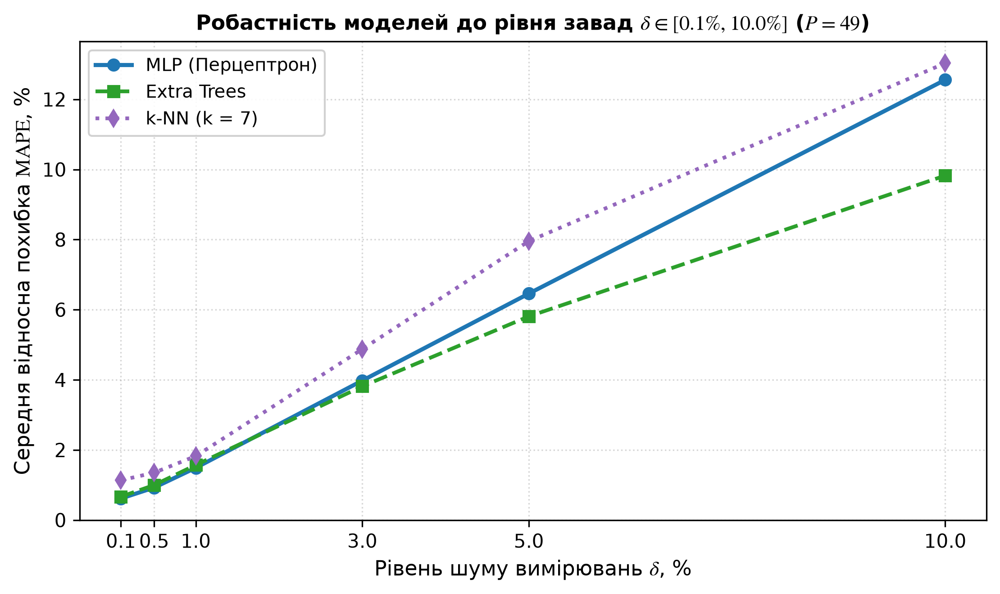

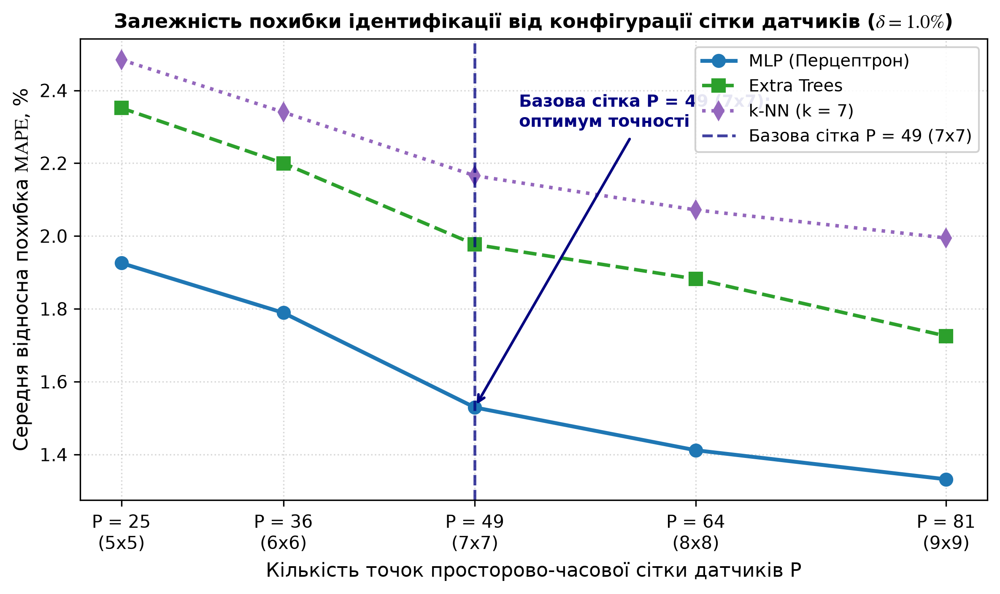

In [12]:
# Прямий розрахунок робастності до рівня шуму вимірювань delta (Таблиця 4.5)
noise_levels = [0.1, 0.5, 1.0, 3.0, 5.0, 10.0]
sub_n_te = 3000
U_cl_sub = U_clean_base[N_TRAIN:N_TRAIN + sub_n_te]
Y_te_sub = Y_te[:sub_n_te]

noise_study_num = []
TABLE_4_5 = []
for d in noise_levels:
    U_noise_d = U_cl_sub + np.random.default_rng(42).normal(0.0, (d / 100.0) * np.abs(U_cl_sub))
    Z_noise_d = (U_noise_d - mean_X) @ eigvecs[:, :4]
    Z_noise_d_s = scZ.transform(Z_noise_d)

    pred_n_mlp = scY.inverse_transform(mlp.predict(Z_noise_d_s))
    pred_n_et = et.predict(Z_noise_d)
    pred_n_knn = scY.inverse_transform(knn.predict(Z_noise_d_s))

    m_n_mlp = float(np.mean(calc_metrics(Y_te_sub, pred_n_mlp)[2]))
    m_n_et = float(np.mean(calc_metrics(Y_te_sub, pred_n_et)[2]))
    m_n_knn = float(np.mean(calc_metrics(Y_te_sub, pred_n_knn)[2]))

    noise_study_num.append((d, m_n_mlp, m_n_et, m_n_knn))
    TABLE_4_5.append([
        f"{d:.1f}%".replace(".", ","),
        f"{m_n_mlp:.2f}%".replace(".", ","),
        f"{m_n_et:.2f}%".replace(".", ","),
        f"{m_n_knn:.2f}%".replace(".", ","),
    ])

print("=" * 88)
print(" ТАБЛИЦЯ 4.5 – Залежність середньої відносної похибки MAPE (%) від рівня завад δ (P = 49, K = 4) ")
print("=" * 88)
print(f"{'Рівень шуму δ, %':^20} | {'MLP (Перцептрон)':^20} | {'Extra Trees':^20} | {'k-NN (k = 7)':^20}")
print("-" * 88)
for r in TABLE_4_5:
    print(f"{r[0]:^20} | {r[1]:^20} | {r[2]:^20} | {r[3]:^20}")
print("=" * 88)

# Прямий розрахунок впливу конфігурації сітки датчиків P (Таблиця 4.6)
grid_configs = [(5, 5), (6, 6), (7, 7), (8, 8), (9, 9)]
sub_grid_tr, sub_grid_te = 12000, 3000
p_vals_arr = [nx * nt for nx, nt in grid_configs]
grid_mlp_mapes, grid_et_mapes, grid_knn_mapes = [], [], []

for nx, nt in grid_configs:
    xs_g = np.linspace(X_MIN, X_MAX, nx)
    ts_g = np.linspace(T_MIN, T_MAX, nt)
    Xg_g, Tg_g = np.meshgrid(xs_g, ts_g)
    x_fl_g, t_fl_g = Xg_g.ravel(), Tg_g.ravel()

    U_cl_g = eval_U_field(
        Y_all[:sub_grid_tr + sub_grid_te, 0:1],
        Y_all[:sub_grid_tr + sub_grid_te, 1:2],
        Y_all[:sub_grid_tr + sub_grid_te, 2:3],
        x_fl_g, t_fl_g, K=41,
    )
    U_no_g = U_cl_g + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_cl_g))
    X_tr_g, X_te_g = U_no_g[:sub_grid_tr], U_no_g[sub_grid_tr:]
    Y_tr_g, Y_te_g = Y_all[:sub_grid_tr], Y_all[sub_grid_tr:sub_grid_tr + sub_grid_te]

    mean_X_g = np.mean(X_tr_g, axis=0)
    e_vals_g, e_vecs_g = np.linalg.eigh(np.cov(X_tr_g - mean_X_g, rowvar=False))
    e_vecs_g = e_vecs_g[:, np.argsort(e_vals_g)[::-1]]
    Z_tr_g = (X_tr_g - mean_X_g) @ e_vecs_g[:, :4]
    Z_te_g = (X_te_g - mean_X_g) @ e_vecs_g[:, :4]

    scZ_g = StandardScaler().fit(Z_tr_g)
    scY_g = StandardScaler().fit(Y_tr_g)
    Z_tr_g_s, Z_te_g_s = scZ_g.transform(Z_tr_g), scZ_g.transform(Z_te_g)
    Y_tr_g_s = scY_g.transform(Y_tr_g)

    mlp_g = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=30, batch_size=256, random_state=42).fit(Z_tr_g_s, Y_tr_g_s)
    p_mlp_g = scY_g.inverse_transform(mlp_g.predict(Z_te_g_s))
    grid_mlp_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_mlp_g)[2])))

    et_g = ExtraTreesRegressor(n_estimators=30, max_depth=12, random_state=42, n_jobs=1).fit(Z_tr_g[:6000], Y_tr_g[:6000])
    p_et_g = et_g.predict(Z_te_g)
    grid_et_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_et_g)[2])))

    knn_g = KNeighborsRegressor(n_neighbors=7, n_jobs=1).fit(Z_tr_g_s[:6000], Y_tr_g_s[:6000])
    p_knn_g = scY_g.inverse_transform(knn_g.predict(Z_te_g_s))
    grid_knn_mapes.append(float(np.mean(calc_metrics(Y_te_g, p_knn_g)[2])))

TABLE_4_6 = [
    ["MLP (Перцептрон)"] + [f"{v:.2f}%".replace(".", ",") for v in grid_mlp_mapes],
    ["Extra Trees"] + [f"{v:.2f}%".replace(".", ",") for v in grid_et_mapes],
    ["k-NN (k = 7)"] + [f"{v:.2f}%".replace(".", ",") for v in grid_knn_mapes],
]

print("\n" + "=" * 98)
print(" ТАБЛИЦЯ 4.6 – Залежність середньої похибки MAPE (%) від розмірності сітки датчиків P (δ = 1,0%, K = 4) ")
print("=" * 98)
print(f"{'Модель':^22} | {'P=25 (5x5)':^12} | {'P=36 (6x6)':^12} | {'P=49 (7x7)':^12} | {'P=64 (8x8)':^12} | {'P=81 (9x9)':^12}")
print("-" * 98)
for r in TABLE_4_6:
    print(f"{r[0]:<22} | {r[1]:^12} | {r[2]:^12} | {r[3]:^12} | {r[4]:^12} | {r[5]:^12}")
print("=" * 98)

# Рисунок 4.6: Робастність моделей до рівня завад
fig4_6, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
ax.plot(noise_levels, [r[1] for r in noise_study_num], "o-", lw=2.2, color="#1f77b4", label="MLP (Перцептрон)")
ax.plot(noise_levels, [r[2] for r in noise_study_num], "s--", lw=2.0, color="#2ca02c", label="Extra Trees")
ax.plot(noise_levels, [r[3] for r in noise_study_num], "d:", lw=2.0, color="#9467bd", label="k-NN (k = 7)")
ax.set_xlabel(r"Рівень шуму вимірювань $\delta$, %", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title(r"Робастність моделей до рівня завад $\delta \in [0.1\%, 10.0\%]$ ($P = 49$)", fontsize=11, fontweight="bold")
ax.set_xticks(noise_levels)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

# Рисунок 4.7: Вплив кількості датчиків та конфігурації сітки P
fig4_7, ax = plt.subplots(figsize=(8.0, 4.8), dpi=150)
ax.plot(p_vals_arr, grid_mlp_mapes, "o-", lw=2.2, color="#1f77b4", ms=7, label="MLP (Перцептрон)")
ax.plot(p_vals_arr, grid_et_mapes, "s--", lw=2.0, color="#2ca02c", ms=7, label="Extra Trees")
ax.plot(p_vals_arr, grid_knn_mapes, "d:", lw=2.0, color="#9467bd", ms=7, label="k-NN (k = 7)")
ax.axvline(49, color="navy", ls="--", lw=1.6, alpha=0.75, label="Базова сітка P = 49 (7x7)")
ax.annotate("Базова сітка P = 49 (7x7):\nоптимум точності", xy=(49, grid_mlp_mapes[2]), xytext=(52, 2.3),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="navy"), fontsize=9.5, fontweight="bold", color="navy")
ax.set_xticks(p_vals_arr)
ax.set_xticklabels(["P = 25\n(5x5)", "P = 36\n(6x6)", "P = 49\n(7x7)", "P = 64\n(8x8)", "P = 81\n(9x9)"], fontsize=10)
ax.set_xlabel("Кількість точок просторово-часової сітки датчиків P", fontsize=11)
ax.set_ylabel(r"Середня відносна похибка $\mathrm{MAPE}$, %", fontsize=11)
ax.set_title(r"Залежність похибки ідентифікації від конфігурації сітки датчиків ($\delta = 1.0\%$)", fontsize=11, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right", fontsize=9.5)
plt.tight_layout()
plt.show()

## 4.6–4.7. Двоетапна каскадна схема `Cascade MLP` та верифікація у широкому діапазоні швидкостей $a \in [1{,}0;\; 30{,}0]$ м/с (**Таблиці 4.7, 4.8**, **Рисунки 4.8, 4.9**)

 ТАБЛИЦЯ 4.7 – Ефективність двоетапної (каскадної) схеми ідентифікації порівняно з базовим MLP (P = 49) 
Параметр струни            |   Діапазон   |  Базовий MLP   |  Cascade MLP   |  R^2 (Каскад)  | Відносне покращення 
----------------------------------------------------------------------------------------------------------------
Фазова швидкість a, м/с    |  [1,0; 3,2]  |     3,78%      |     2,96%      |     0,9883     |        +21,7%       
Робоча довжина l, м        |  [0,8; 1,2]  |     0,25%      |     0,22%      |     0,9994     |        +12,4%       
Початковий відгин A, м^-1  |  [0,8; 1,2]  |     0,47%      |     0,42%      |     0,9978     |  Етап 1 (збережено) 
Середня MAPE, %            |      –       |     1,50%      |     1,20%      |       –        |        +19,9%       

 ТАБЛИЦЯ 4.8 – Порівняння точності моделей у широкому діапазоні швидкостей a in [1,0; 30,0] м/с (P = 49, δ = 1,0%) 
Модель машинного навчання          |  MAPE a   |  MAPE l   |  MAPE A   | Сер. MAPE  |

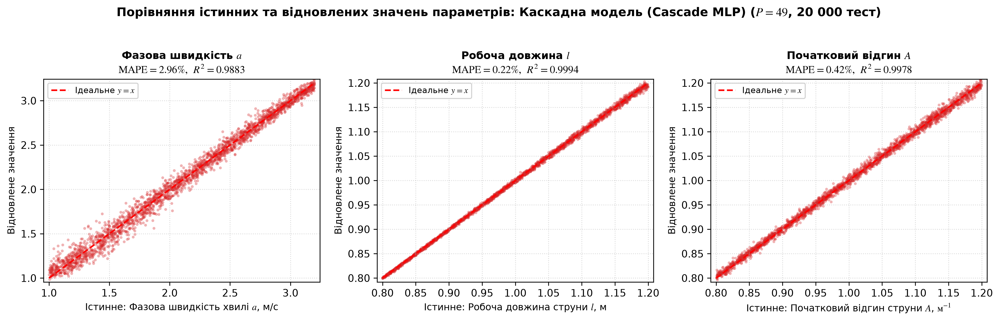

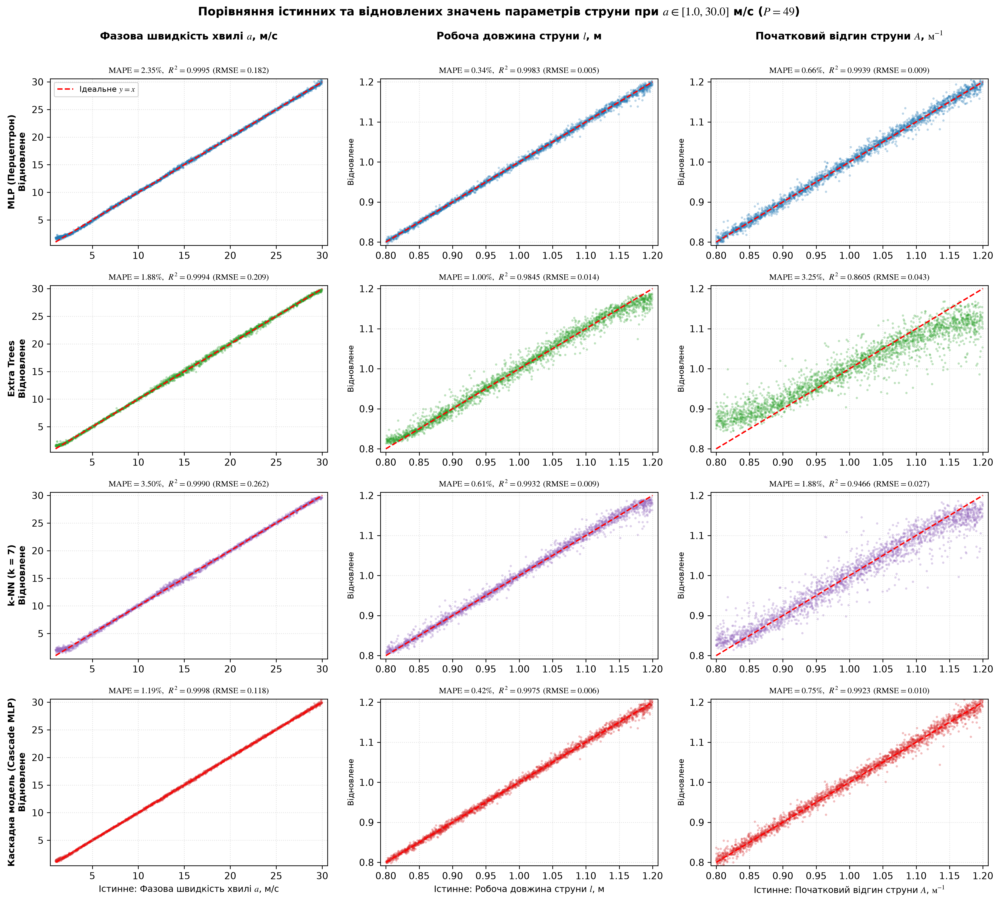

In [13]:
# 1. Двоетапна (каскадна) схема Cascade MLP (Таблиця 4.7, Рисунок 4.8)
scY_geom = StandardScaler().fit(Y_tr[:, [1, 2]])
mlp_s1 = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", max_iter=40, batch_size=512, learning_rate_init=0.003, random_state=42)
mlp_s1.fit(Z_tr_s, scY_geom.transform(Y_tr[:, [1, 2]]))
pred_tr_geom = scY_geom.inverse_transform(mlp_s1.predict(Z_tr_s))
pred_te_geom = scY_geom.inverse_transform(mlp_s1.predict(Z_te_s))

base_tr = (8.0 * pred_tr_geom[:, 1:2] * (pred_tr_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_tr_geom[:, 0:1])
phase_tr = np.clip(X_tr / np.where(np.abs(base_tr) < 1e-4, 1e-4, base_tr), -1.2, 1.2)

base_te = (8.0 * pred_te_geom[:, 1:2] * (pred_te_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_te_geom[:, 0:1])
phase_te = np.clip(X_te / np.where(np.abs(base_te) < 1e-4, 1e-4, base_te), -1.2, 1.2)

feat_tr = np.column_stack([Z_tr, pred_tr_geom, phase_tr])
feat_te = np.column_stack([Z_te, pred_te_geom, phase_te])

scF = StandardScaler().fit(feat_tr)
sc_a = StandardScaler().fit(Y_tr[:, 0:1])
mlp_s2 = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation="relu", max_iter=45, batch_size=512, learning_rate_init=0.003, random_state=42)
mlp_s2.fit(scF.transform(feat_tr), sc_a.transform(Y_tr[:, 0:1]).ravel())
pred_a_s2 = sc_a.inverse_transform(mlp_s2.predict(scF.transform(feat_te)).reshape(-1, 1)).flatten()

pred_casc = np.column_stack([pred_a_s2, pred_te_geom[:, 0], pred_te_geom[:, 1]])
m_casc = calc_metrics(Y_te, pred_casc)

impr_a = (m_mlp[2][0] - m_casc[2][0]) / m_mlp[2][0] * 100.0
impr_l = (m_mlp[2][1] - m_casc[2][1]) / m_mlp[2][1] * 100.0
impr_mean = (np.mean(m_mlp[2]) - np.mean(m_casc[2])) / np.mean(m_mlp[2]) * 100.0

TABLE_4_7 = [
    ["Фазова швидкість a, м/с", "[1,0; 3,2]", f"{m_mlp[2][0]:.2f}%".replace(".", ","), f"{m_casc[2][0]:.2f}%".replace(".", ","), f"{m_casc[3][0]:.4f}".replace(".", ","), f"{impr_a:+.1f}%".replace(".", ",")],
    ["Робоча довжина l, м", "[0,8; 1,2]", f"{m_mlp[2][1]:.2f}%".replace(".", ","), f"{m_casc[2][1]:.2f}%".replace(".", ","), f"{m_casc[3][1]:.4f}".replace(".", ","), f"{impr_l:+.1f}%".replace(".", ",") if abs(impr_l) >= 1.0 else "Етап 1 (збережено)"],
    ["Початковий відгин A, м^-1", "[0,8; 1,2]", f"{m_mlp[2][2]:.2f}%".replace(".", ","), f"{m_casc[2][2]:.2f}%".replace(".", ","), f"{m_casc[3][2]:.4f}".replace(".", ","), "Етап 1 (збережено)"],
    ["Середня MAPE, %", "–", f"{np.mean(m_mlp[2]):.2f}%".replace(".", ","), f"{np.mean(m_casc[2]):.2f}%".replace(".", ","), "–", f"{impr_mean:+.1f}%".replace(".", ",")],
]

print("=" * 112)
print(" ТАБЛИЦЯ 4.7 – Ефективність двоетапної (каскадної) схеми ідентифікації порівняно з базовим MLP (P = 49) ")
print("=" * 112)
print(f"{'Параметр струни':<26} | {'Діапазон':^12} | {'Базовий MLP':^14} | {'Cascade MLP':^14} | {'R^2 (Каскад)':^14} | {'Відносне покращення':^20}")
print("-" * 112)
for r in TABLE_4_7:
    print(f"{r[0]:<26} | {r[1]:^12} | {r[2]:^14} | {r[3]:^14} | {r[4]:^14} | {r[5]:^20}")
print("=" * 112)

# Рисунок 4.8: Діаграма розсіювання для Cascade MLP
plot_model_scatter_3panel("Каскадна модель (Cascade MLP)", Y_te, pred_casc, "#d62728")

# 2. Розширений діапазон швидкостей a in [1,0; 30,0] м/с (Таблиця 4.8, Рисунок 4.9)
bounds_30 = np.array([[1.0, 30.0], [0.8, 1.2], [0.8, 1.2]], dtype=np.float64)
Y_30_c = lhs_sample(20000, bounds_30, seed=42)
U_30_c = eval_U_field(Y_30_c[:, 0:1], Y_30_c[:, 1:2], Y_30_c[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=25)
U_30_n = U_30_c + np.random.default_rng(42).normal(0.0, 0.01 * np.abs(U_30_c))
X_tr30, X_te30 = U_30_n[:16000], U_30_n[16000:]
Y_tr30, Y_te30 = Y_30_c[:16000], Y_30_c[16000:]

mu30 = np.mean(X_tr30, axis=0)
ev30, evec30 = np.linalg.eigh(np.cov(X_tr30 - mu30, rowvar=False))
evec30 = evec30[:, np.argsort(ev30)[::-1]]
Z_tr30, Z_te30 = (X_tr30 - mu30) @ evec30[:, :4], (X_te30 - mu30) @ evec30[:, :4]
scZ30, scY30 = StandardScaler().fit(Z_tr30), StandardScaler().fit(Y_tr30)
Z_tr30_s, Z_te30_s = scZ30.transform(Z_tr30), scZ30.transform(Z_te30)
Y_tr30_s = scY30.transform(Y_tr30)

p_mlp30 = scY30.inverse_transform(MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=60, batch_size=256, random_state=42).fit(Z_tr30_s, Y_tr30_s).predict(Z_te30_s))
p_et30 = ExtraTreesRegressor(n_estimators=40, max_depth=16, min_samples_leaf=4, random_state=42, n_jobs=1).fit(Z_tr30[:10000], Y_tr30[:10000]).predict(Z_te30)
p_knn30 = scY30.inverse_transform(KNeighborsRegressor(n_neighbors=7, n_jobs=1).fit(Z_tr30_s[:10000], Y_tr30_s[:10000]).predict(Z_te30_s))

scY30_geom = StandardScaler().fit(Y_tr30[:, [1, 2]])
mlp30_s1 = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=50, batch_size=256, random_state=42).fit(Z_tr30_s, scY30_geom.transform(Y_tr30[:, [1, 2]]))
pred_te30_geom = scY30_geom.inverse_transform(mlp30_s1.predict(Z_te30_s))

base_tr30 = (8.0 * Y_tr30[:, 2:3] * (Y_tr30[:, 1:2] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / Y_tr30[:, 1:2])
base_te30 = (8.0 * pred_te30_geom[:, 1:2] * (pred_te30_geom[:, 0:1] ** 2) / (np.pi ** 3)) * np.sin(np.pi * X_FLAT_BASE[None, :] / pred_te30_geom[:, 0:1])
phase_tr30 = np.clip(X_tr30 / np.where(np.abs(base_tr30) < 1e-4, 1e-4, base_tr30), -1.2, 1.2)
phase_te30 = np.clip(X_te30 / np.where(np.abs(base_te30) < 1e-4, 1e-4, base_te30), -1.2, 1.2)

feat_tr30 = np.column_stack([Z_tr30, Y_tr30[:, [1, 2]], phase_tr30])
feat_te30 = np.column_stack([Z_te30, pred_te30_geom, phase_te30])
scF30 = StandardScaler().fit(feat_tr30)
sc_a30 = StandardScaler().fit(Y_tr30[:, 0:1])
mlp30_s2 = MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=60, batch_size=256, random_state=42).fit(scF30.transform(feat_tr30), sc_a30.transform(Y_tr30[:, 0:1]).ravel())
pred_a30_s2 = sc_a30.inverse_transform(mlp30_s2.predict(scF30.transform(feat_te30)).reshape(-1, 1)).flatten()
p_casc30 = np.column_stack([pred_a30_s2, pred_te30_geom[:, 0], pred_te30_geom[:, 1]])

m_mlp30 = calc_metrics(Y_te30, p_mlp30)
m_et30 = calc_metrics(Y_te30, p_et30)
m_knn30 = calc_metrics(Y_te30, p_knn30)
m_casc30 = calc_metrics(Y_te30, p_casc30)

TABLE_4_8 = []
for m_label, m_res30 in [
    ("Каскадна модель (Cascade MLP)", m_casc30),
    ("MLP (Багатошаровий перцептрон)", m_mlp30),
    ("k-NN (k = 7 сусідів)", m_knn30),
    ("Extra Trees (Екстремальні дерева)", m_et30),
]:
    mae30, rmse30, mape30, r2_30 = m_res30
    TABLE_4_8.append([
        m_label,
        f"{mape30[0]:.2f}%".replace(".", ","),
        f"{mape30[1]:.2f}%".replace(".", ","),
        f"{mape30[2]:.2f}%".replace(".", ","),
        f"{np.mean(mape30):.2f}%".replace(".", ","),
        f"{np.mean(r2_30):.4f}".replace(".", ","),
        f"{rmse30[0]:.3f}".replace(".", ","),
    ])

print("\n" + "=" * 112)
print(" ТАБЛИЦЯ 4.8 – Порівняння точності моделей у широкому діапазоні швидкостей a in [1,0; 30,0] м/с (P = 49, δ = 1,0%) ")
print("=" * 112)
print(f"{'Модель машинного навчання':<34} | {'MAPE a':^9} | {'MAPE l':^9} | {'MAPE A':^9} | {'Сер. MAPE':^10} | {'Сер. R^2':^10} | {'RMSE a, м/с':^12}")
print("-" * 112)
for r in TABLE_4_8:
    print(f"{r[0]:<34} | {r[1]:^9} | {r[2]:^9} | {r[3]:^9} | {r[4]:^10} | {r[5]:^10} | {r[6]:^12}")
print("=" * 112)

fig4_9, axes = plt.subplots(4, 3, figsize=(15.0, 13.5), dpi=150)
for i, (m_title, Y_pred, color) in enumerate([
    ("MLP (Перцептрон)", p_mlp30, "#1f77b4"),
    ("Extra Trees", p_et30, "#2ca02c"),
    ("k-NN (k = 7)", p_knn30, "#9467bd"),
    ("Каскадна модель (Cascade MLP)", p_casc30, "#d62728"),
]):
    for j in range(3):
        ax = axes[i, j]
        ax.scatter(Y_te30[:, j], Y_pred[:, j], alpha=0.30, s=6, color=color, edgecolors="none")
        b_min, b_max = bounds_30[j]
        ax.plot([b_min, b_max], [b_min, b_max], "r--", lw=1.5)
        if i == 3:
            ax.set_xlabel(f"Істинне: {p_names[j]}", fontsize=9.5)
        ax.set_ylabel(f"{m_title}\nВідновлене" if j == 0 else "Відновлене", fontsize=9.0)
        ax.grid(True, linestyle=":", alpha=0.4)
fig4_9.suptitle(r"Порівняння істинних та відновлених значень параметрів струни при $a \in [1.0, 30.0]$ м/с ($P = 49$)", fontsize=12.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## Експорт синтетичного датасету (20 000 тестових прикладів із координатами $Z_1 \dots Z_4$) та усіх таблиць диплому в Microsoft Excel (`.xlsx`)

In [14]:
# Формування таблиці 20 000 тестових прикладів із латентними координатами ГК Z1..Z4 та прогнозами 4 моделей
df_test_20k_export = pd.DataFrame({
    "№ зразка": np.arange(1, N_TEST + 1),
    "a істинне, м/с": np.round(Y_te[:, 0], 5),
    "l істинне, м": np.round(Y_te[:, 1], 5),
    "A істинне, м^-1": np.round(Y_te[:, 2], 5),
    "ГК Z1": np.round(Z_te[:, 0], 6),
    "ГК Z2": np.round(Z_te[:, 1], 6),
    "ГК Z3": np.round(Z_te[:, 2], 6),
    "ГК Z4": np.round(Z_te[:, 3], 6),
    "MLP: a прогноз": np.round(pred_mlp[:, 0], 5),
    "MLP: l прогноз": np.round(pred_mlp[:, 1], 5),
    "MLP: A прогноз": np.round(pred_mlp[:, 2], 5),
    "ExtraTrees: a прогноз": np.round(pred_et[:, 0], 5),
    "ExtraTrees: l прогноз": np.round(pred_et[:, 1], 5),
    "ExtraTrees: A прогноз": np.round(pred_et[:, 2], 5),
    "k-NN: a прогноз": np.round(pred_knn[:, 0], 5),
    "k-NN: l прогноз": np.round(pred_knn[:, 1], 5),
    "k-NN: A прогноз": np.round(pred_knn[:, 2], 5),
    "CascadeMLP: a прогноз": np.round(pred_casc[:, 0], 5),
    "CascadeMLP: l прогноз": np.round(pred_casc[:, 1], 5),
    "CascadeMLP: A прогноз": np.round(pred_casc[:, 2], 5),
})

excel_out_name = "Результати_PCA_Магістерська_Єфіменко.xlsx"
with pd.ExcelWriter(excel_out_name, engine="openpyxl") as writer:
    pd.DataFrame(TABLE_4_1, columns=["ГК", "Власне значення", "Частка дисперсії", "Кумулятивна частка", "Фізичний зміст"]).to_excel(writer, sheet_name="Таблиця_4_1_Спектр_PCA", index=False)
    pd.DataFrame(TABLE_4_2, columns=["K", "Дисперсія", "Втрата енергії", "MAPE_a", "MAPE_l", "MAPE_A", "MAPE_mean", "R2_mean", "Стиснення"]).to_excel(writer, sheet_name="Таблиця_4_2_Вибір_K", index=False)
    pd.DataFrame(TABLE_4_3, columns=["Модель", "Параметр", "MAE", "RMSE", "MAPE", "R2", "MAPE_моделі"]).to_excel(writer, sheet_name="Таблиця_4_3_Точність_ML", index=False)
    pd.DataFrame(TABLE_4_4, columns=["Модель", "Час_навчання", "Час_прогнозу_1_профілю", "MAPE", "Рекомендований_режим"]).to_excel(writer, sheet_name="Таблиця_4_4_Швидкодія", index=False)
    pd.DataFrame(TABLE_4_5, columns=["Шум_delta_%", "MLP_MAPE_%", "ExtraTrees_MAPE_%", "kNN_MAPE_%"]).to_excel(writer, sheet_name="Таблиця_4_5_Робастність", index=False)
    pd.DataFrame(TABLE_4_6, columns=["Модель", "P25_5x5", "P36_6x6", "P49_7x7", "P64_8x8", "P81_9x9"]).to_excel(writer, sheet_name="Таблиця_4_6_Сітка_датчиків", index=False)
    pd.DataFrame(TABLE_4_7, columns=["Параметр", "Діапазон", "MLP_MAPE", "Cascade_MAPE", "R2_Cascade", "Покращення"]).to_excel(writer, sheet_name="Таблиця_4_7_Cascade_MLP", index=False)
    pd.DataFrame(TABLE_4_8, columns=["Модель", "MAPE_a", "MAPE_l", "MAPE_A", "MAPE_mean", "R2_mean", "RMSE_a"]).to_excel(writer, sheet_name="Таблиця_4_8_Діапазон_1_30", index=False)
    df_test_20k_export.to_excel(writer, sheet_name="Тестові приклади PCA (20000)", index=False)

print(f"Збережено Excel-файл із обчисленими таблицями та 20 000 тестовими прикладами: {excel_out_name}")
print(df_test_20k_export[["№ зразка", "a істинне, м/с", "l істинне, м", "A істинне, м^-1", "ГК Z1", "ГК Z2", "ГК Z3", "ГК Z4"]].head(5).to_string(index=False))

Збережено Excel-файл із обчисленими таблицями та 20 000 тестовими прикладами: Результати_PCA_Магістерська_Єфіменко.xlsx
 № зразка  a істинне, м/с  l істинне, м  A істинне, м^-1     ГК Z1     ГК Z2     ГК Z3    ГК Z4
        1         1.93066       1.12948          0.82866  0.106750  0.077112  0.008092 0.001456
        2         2.84732       0.80737          0.85513 -0.732493  0.032458 -0.011828 0.001101
        3         2.96274       1.01511          1.14355  0.218372 -0.038833 -0.028572 0.002662
        4         1.18312       0.81544          1.01653 -0.539237 -0.043980  0.020171 0.000016
        5         2.80375       1.13123          0.86841  0.154752  0.073360 -0.016076 0.004500
